# RetailPulse — Customer Churn Prediction

### Objective
Predict whether a customer will become inactive during a future prediction window,
using only information available during the historical observation period.

### Key Principles
- No future information in features
- Time-aware train/validation/test split
- Churn definition based on observed purchasing behavior
- Customer-level modeling
- Business-oriented churn risk scoring

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sales_df = pd.read_parquet("../data/processed/clean_sales.parquet")
sales_df.head()

,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4,15CM CHRISTMAS GLASS BALL 20 LIGHTS
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,PINK CHERRY LIGHTS
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0,WHITE CHERRY LIGHTS
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8,"RECORD FRAME 7"" SINGLE SIZE"
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0,STRAWBERRY CERAMIC TRINKET BOX


In [3]:
sales_df.shape

(1007913, 11)

In [4]:
print("Column names:")
print(sales_df.columns.tolist())

print("\nData types:")
display(sales_df.dtypes)

print("\nDataset information:")
sales_df.info()

Column names:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']

Data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1007913 entries, 0 to 1007912
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   invoice            1007913 non-null  string        
 1   stock_code         1007913 non-null  string        
 2   description        1007913 non-null  string        
 3   quantity           1007913 non-null  int64         
 4   invoice_date       1007913 non-null  datetime64[us]
 5   unit_price         1007913 non-null  float64       
 6   customer_id        779425 non-null   Int64         
 7   country            1007913 non-null  string        
 8   is_cancelled       1007913 non-null  bool          
 9   revenue            1007913 non-null  float64       
 10  description_clean  1007913 non-null  string        
dtypes: Int64(1), bool(1), datetime64[us](1), float64(2), int64(1), string(5)
memory usage: 153.7 MB


In [5]:
print("Missing values:")
display(sales_df.isna().sum().sort_values(ascending=False))

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nUnique values:")
for col in sales_df.columns:
    print(f"{col}: {sales_df[col].nunique():,}")

Missing values:


customer_id          228488
stock_code                0
invoice                   0
description               0
quantity                  0
invoice_date              0
unit_price                0
country                   0
is_cancelled              0
revenue                   0
description_clean         0
dtype: int64


Duplicate rows: 0

Unique values:
invoice: 40,077
stock_code: 4,917
description: 5,399
quantity: 520
invoice_date: 37,212
unit_price: 2,275
customer_id: 5,878
country: 43
is_cancelled: 1
revenue: 7,099
description_clean: 5,399


In [6]:
date_candidates = []

for col in sales_df.columns:
    if pd.api.types.is_datetime64_any_dtype(sales_df[col]):
        date_candidates.append(col)

print("Datetime columns:")
print(date_candidates)

Datetime columns:
['invoice_date']


In [7]:
DATE_COL = "invoice_date"

print("Minimum date:", sales_df[DATE_COL].min())
print("Maximum date:", sales_df[DATE_COL].max())

print("\nDate range:")
print(sales_df[DATE_COL].max() - sales_df[DATE_COL].min())

Minimum date: 2009-12-01 07:45:00
Maximum date: 2011-12-09 12:50:00

Date range:
738 days 05:05:00


In [8]:
monthly_sales = (sales_df.set_index(DATE_COL).resample("MS").size())
display(monthly_sales)

invoice_date
2009-12-01    43453
2010-01-01    30317
2010-02-01    27952
2010-03-01    39841
2010-04-01    32858
2010-05-01    33383
2010-06-01    38391
2010-07-01    32112
2010-08-01    32109
2010-09-01    40630
2010-10-01    56953
2010-11-01    75035
2010-12-01    40991
2011-01-01    34060
2011-02-01    26882
2011-03-01    35497
2011-04-01    28882
2011-05-01    35917
2011-06-01    35716
2011-07-01    38395
2011-08-01    34264
2011-09-01    48900
2011-10-01    58537
2011-11-01    82004
2011-12-01    24834
Freq: MS, dtype: int64

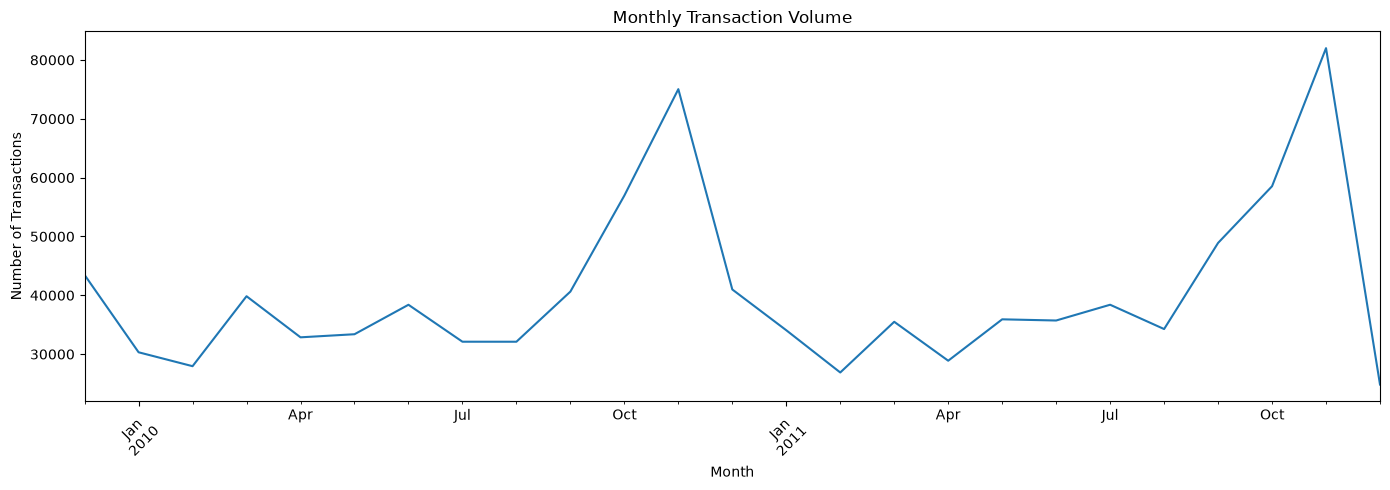

In [9]:
plt.figure(figsize=(14, 5))

monthly_sales.plot()

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# Basic cancellation analysis

print("Cancellation flag distribution:")
display(sales_df["is_cancelled"].value_counts(dropna=False).rename_axis("is_cancelled").to_frame("row_count"))

print("\nCancellation percentage:")
display((sales_df["is_cancelled"].value_counts(normalize=True, dropna=False) * 100).rename("percentage"))

print("\nInvoice count by cancellation status:")

invoice_cancellation = (sales_df.groupby("is_cancelled").agg(unique_invoices=("invoice", "nunique"),unique_customers=("customer_id", "nunique"),total_rows=("invoice", "size"),total_revenue=("revenue", "sum")))

display(invoice_cancellation)

Cancellation flag distribution:


,row_count
is_cancelled,
False,1007913



Cancellation percentage:


is_cancelled
False    100.0
Name: percentage, dtype: float64


Invoice count by cancellation status:


,unique_invoices,unique_customers,total_rows,total_revenue
is_cancelled,,,,
False,40077,5878,1007913,2.047626e+07


In [11]:
# Check whether an invoice has multiple cancellation statuses

invoice_status_counts = (sales_df.groupby("invoice")["is_cancelled"].nunique()
)

mixed_status_invoices = invoice_status_counts[invoice_status_counts > 1]

print("Invoices with inconsistent cancellation status:",len(mixed_status_invoices))

print("Total unique invoices:",sales_df["invoice"].nunique())

if len(mixed_status_invoices) > 0:
    print("\nSample inconsistent invoices:")
    display(sales_df[sales_df["invoice"].isin(mixed_status_invoices.index)].sort_values(["invoice", "invoice_date"]).head(20))

Invoices with inconsistent cancellation status: 0
Total unique invoices: 40077


In [12]:
# Preliminary eligible purchase rows

purchase_rows = sales_df.loc[sales_df["customer_id"].notna()& (~sales_df["is_cancelled"])& sales_df["invoice"].notna()& sales_df["invoice_date"].notna()].copy()

print("Original rows:", len(sales_df))
print("Preliminary purchase rows:", len(purchase_rows))

print("Customers:",purchase_rows["customer_id"].nunique())

print("Invoices:",purchase_rows["invoice"].nunique())

print("Date range:",purchase_rows["invoice_date"].min(),"to",purchase_rows["invoice_date"].max())

Original rows: 1007913
Preliminary purchase rows: 779425
Customers: 5878
Invoices: 36969
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [13]:
# Aggregate product rows into customer-level invoices

invoice_level = (purchase_rows.groupby(["customer_id", "invoice"], as_index=False).agg(
        invoice_date=("invoice_date", "min"),
        invoice_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        unique_products=("stock_code", "nunique"),
        invoice_rows=("stock_code", "size")
    )
)

print("Invoice-level dataset shape:", invoice_level.shape)

display(invoice_level.head())

print("\nInvoice-level summary:")
display(invoice_level[["invoice_revenue","total_quantity","unique_products","invoice_rows"]].describe())

Invoice-level dataset shape: (36969, 7)


,customer_id,invoice,invoice_date,invoice_revenue,total_quantity,unique_products,invoice_rows
0,12346,491725,2009-12-14 08:34:00,45.0,10,1,1
1,12346,491742,2009-12-14 11:00:00,22.5,5,1,1
2,12346,491744,2009-12-14 11:02:00,22.5,5,1,1
3,12346,492718,2009-12-18 10:47:00,22.5,5,1,1
4,12346,492722,2009-12-18 10:55:00,1.0,1,1,1



Invoice-level summary:


,invoice_revenue,total_quantity,unique_products,invoice_rows
count,36969.000000,36969.000000,36969.000000,36969.0
mean,469.983074,284.399145,20.797560,21.083205
std,1359.741927,1232.382259,22.399873,22.964763
min,0.380000,1.000000,1.000000,1.0
25%,157.920000,72.000000,6.000000,6.0
50%,303.040000,151.000000,15.000000,15.0
75%,477.280000,287.000000,27.000000,27.0
max,168469.600000,87167.000000,541.000000,542.0


In [14]:
customer_purchase_counts = (invoice_level.groupby("customer_id").agg(
        purchase_count=("invoice", "nunique"),
        first_purchase=("invoice_date", "min"),
        last_purchase=("invoice_date", "max"),
        total_revenue=("invoice_revenue", "sum"),
        total_quantity=("total_quantity", "sum")
    )
)

print("Customer summary shape:", customer_purchase_counts.shape)

display(customer_purchase_counts[["purchase_count","total_revenue","total_quantity"]].describe())

Customer summary shape: (5878, 5)


,purchase_count,total_revenue,total_quantity
count,5878.000000,5878.000000,5878.000000
mean,6.289384,2955.904095,1788.695475
std,13.009406,14440.852688,8876.297196
min,1.000000,2.950000,1.000000
25%,1.000000,342.280000,187.000000
50%,3.000000,867.740000,480.000000
75%,7.000000,2248.305000,1350.000000
max,398.000000,580987.040000,367193.000000


In [15]:
# Purchase frequency distribution

purchase_frequency_distribution = (customer_purchase_counts["purchase_count"].value_counts().sort_index())

display(purchase_frequency_distribution.head(20))

print("\nCustomers with only one observed purchase:")
print((customer_purchase_counts["purchase_count"] == 1).sum())

print("\nCustomers with at least two observed purchases:")
print((customer_purchase_counts["purchase_count"] >= 2).sum())

print("\nCustomers with at least five observed purchases:")
print((customer_purchase_counts["purchase_count"] >= 5).sum())

purchase_count
1     1623
2      944
3      664
4      486
5      360
6      280
7      222
8      172
9      153
10      98
11     131
12      96
13      79
14      49
15      51
16      43
17      41
18      32
19      26
20      31
Name: count, dtype: int64


Customers with only one observed purchase:
1623

Customers with at least two observed purchases:
4255

Customers with at least five observed purchases:
2161


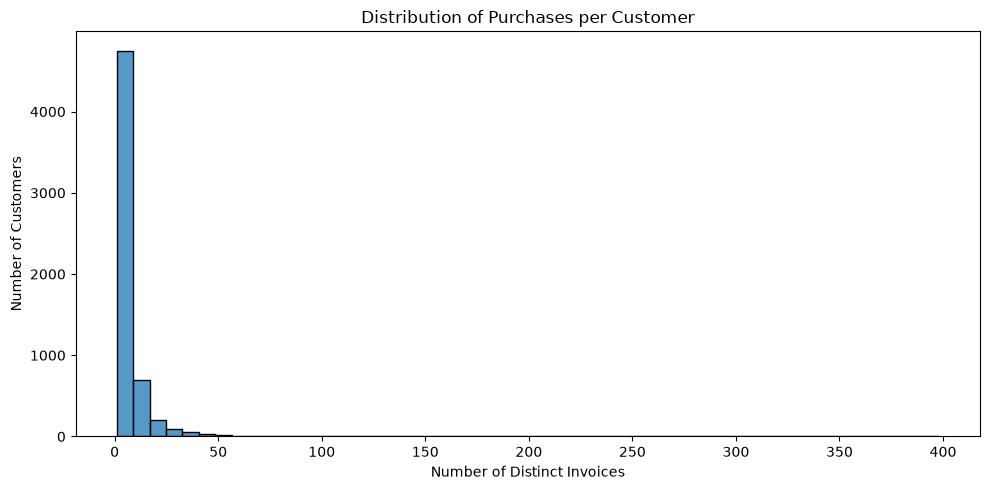

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(data=customer_purchase_counts,x="purchase_count",bins=50)

plt.title("Distribution of Purchases per Customer")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

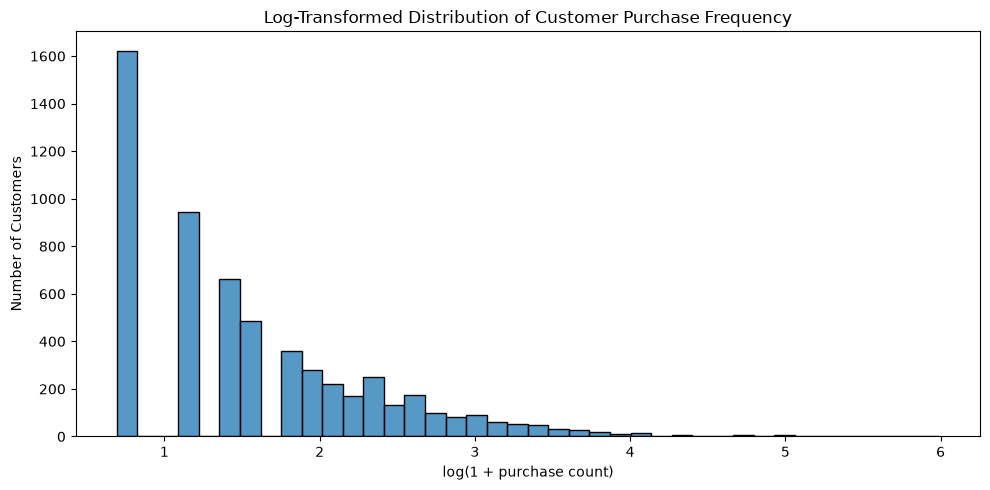

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(np.log1p(customer_purchase_counts["purchase_count"]),bins=40)

plt.title("Log-Transformed Distribution of Customer Purchase Frequency")
plt.xlabel("log(1 + purchase count)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [18]:
# Sort invoices chronologically

invoice_level = invoice_level.sort_values(["customer_id", "invoice_date", "invoice"]).reset_index(drop=True)

# Days between consecutive invoices for each customer

invoice_level["days_since_previous_purchase"] = (invoice_level.groupby("customer_id")["invoice_date"].diff().dt.total_seconds().div(86400))

interpurchase_intervals = invoice_level.loc[invoice_level["days_since_previous_purchase"].notna(),
    [
        "customer_id",
        "invoice",
        "invoice_date",
        "days_since_previous_purchase"
    ]
].copy()

print("Number of observed interpurchase intervals:",len(interpurchase_intervals))

display(interpurchase_intervals["days_since_previous_purchase"].describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]))

Number of observed interpurchase intervals: 31091


count    31091.000000
mean        51.686656
std         75.788911
min          0.000000
10%          0.013194
25%          6.983333
50%         24.743056
75%         61.810417
90%        134.875694
95%        206.426736
max        714.152083
Name: days_since_previous_purchase, dtype: float64

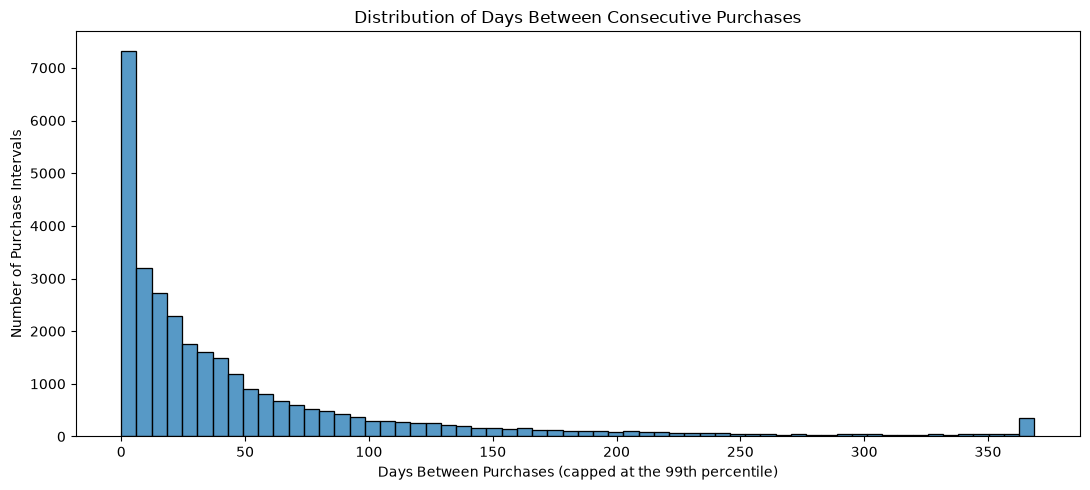

In [19]:
intervals = interpurchase_intervals["days_since_previous_purchase"]

plt.figure(figsize=(11, 5))

sns.histplot(intervals.clip(upper=intervals.quantile(0.99)),bins=60)

plt.title("Distribution of Days Between Consecutive Purchases")
plt.xlabel("Days Between Purchases (capped at the 99th percentile)")
plt.ylabel("Number of Purchase Intervals")
plt.tight_layout()
plt.show()

In [20]:
interval_percentiles = (interpurchase_intervals["days_since_previous_purchase"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .rename_axis("percentile")
    .to_frame("days_between_purchases")
)

display(interval_percentiles)

,days_between_purchases
percentile,
0.10,0.013194
0.25,6.983333
0.50,24.743056
0.75,61.810417
0.90,134.875694
0.95,206.426736
0.99,368.740764


In [21]:
customer_cadence = (interpurchase_intervals.groupby("customer_id").agg(
        observed_intervals=("days_since_previous_purchase","size"),
        median_days_between_purchases=("days_since_previous_purchase","median"),
        mean_days_between_purchases=("days_since_previous_purchase","mean"),
        p90_days_between_purchases=("days_since_previous_purchase",lambda x: x.quantile(0.90))
    )
)

display(customer_cadence[
        [
            "observed_intervals",
            "median_days_between_purchases",
            "mean_days_between_purchases",
            "p90_days_between_purchases"
        ]
    ].describe()
)

,observed_intervals,median_days_between_purchases,mean_days_between_purchases,p90_days_between_purchases
count,4255.000000,4255.000000,4255.000000,4255.000000
mean,7.306933,92.714992,102.300645,148.314149
std,14.801008,101.177919,98.277152,113.272025
min,1.000000,0.000000,0.000000,0.000000
25%,2.000000,28.079861,38.576845,62.631806
50%,4.000000,55.972222,72.335880,121.904167
75%,8.000000,118.185764,129.843750,204.801111
max,397.000000,714.152083,714.152083,714.152083


In [22]:
monthly_customer_activity = (invoice_level.assign(month=lambda df: (df["invoice_date"].dt.to_period("M"))).groupby("month")
    .agg(
        unique_customers=("customer_id", "nunique"),
        unique_invoices=("invoice", "nunique"),
        total_revenue=("invoice_revenue", "sum")
    )
)

display(monthly_customer_activity)

,unique_customers,unique_invoices,total_revenue
month,,,
2009-12,955,1512,683504.010
2010-01,720,1011,555802.672
2010-02,772,1104,504558.956
2010-03,1057,1524,696978.471
2010-04,942,1329,591982.002
2010-05,966,1377,597833.380
2010-06,1041,1497,636371.130
2010-07,928,1381,589736.170
2010-08,911,1293,602224.600


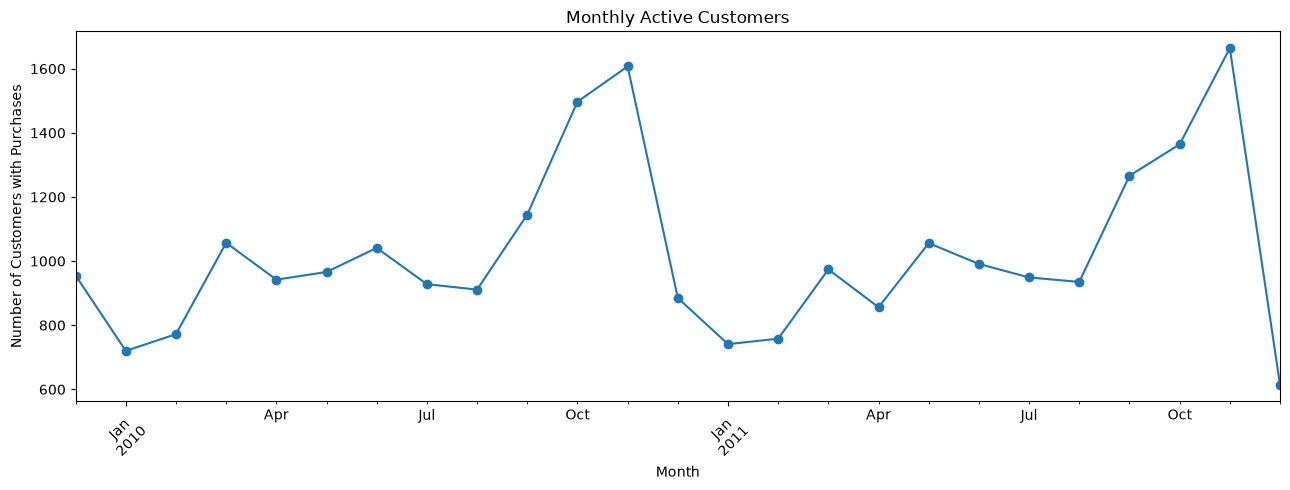

In [23]:
plt.figure(figsize=(13, 5))

monthly_customer_activity["unique_customers"].plot(marker="o")

plt.title("Monthly Active Customers")
plt.xlabel("Month")
plt.ylabel("Number of Customers with Purchases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

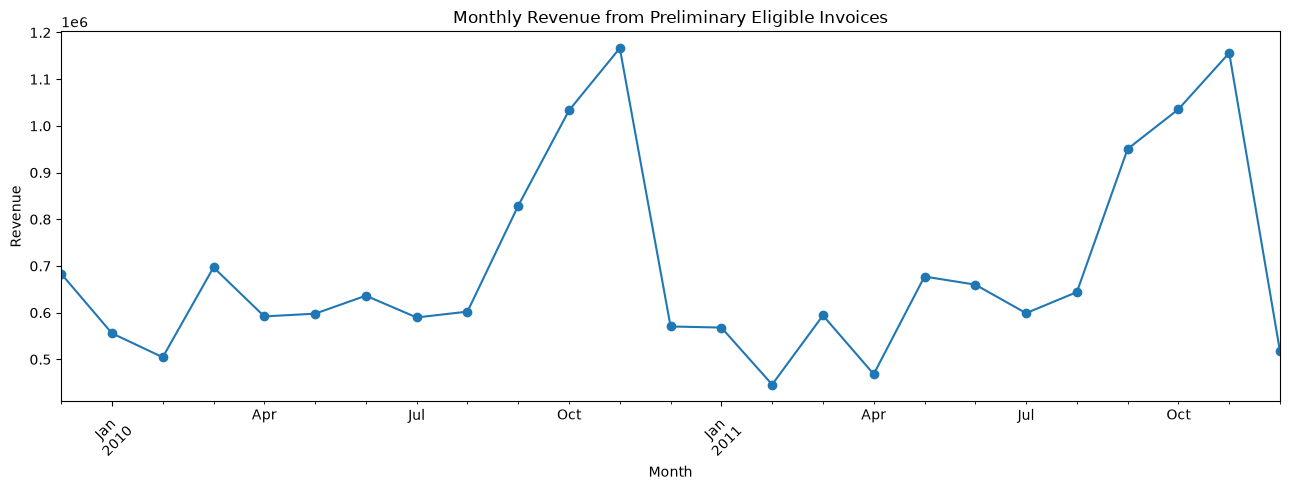

In [24]:
plt.figure(figsize=(13, 5))

monthly_customer_activity["total_revenue"].plot(marker="o")

plt.title("Monthly Revenue from Preliminary Eligible Invoices")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# Inspect quantities and revenue in the original dataset

print("Quantity distribution:")
display(sales_df["quantity"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nRevenue distribution:")
display(sales_df["revenue"].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

print("\nNegative quantity rows:")
print((sales_df["quantity"] < 0).sum())

print("\nZero quantity rows:")
print((sales_df["quantity"] == 0).sum())

print("\nNegative revenue rows:")
print((sales_df["revenue"] < 0).sum())

print("\nZero revenue rows:")
print((sales_df["revenue"] == 0).sum())

Quantity distribution:


count    1.007913e+06
mean     1.111718e+01
std      1.284700e+02
min      1.000000e+00
1%       1.000000e+00
5%       1.000000e+00
25%      1.000000e+00
50%      4.000000e+00
75%      1.200000e+01
95%      3.100000e+01
99%      1.080000e+02
max      8.099500e+04
Name: quantity, dtype: float64


Revenue distribution:


count    1.007913e+06
mean     2.031550e+01
std      2.057158e+02
min      1.000000e-03
1%       6.500000e-01
5%       1.250000e+00
25%      4.130000e+00
50%      1.008000e+01
75%      1.770000e+01
95%      6.000000e+01
99%      1.845880e+02
max      1.684696e+05
Name: revenue, dtype: float64


Negative quantity rows:
0

Zero quantity rows:
0

Negative revenue rows:
0

Zero revenue rows:
0


In [26]:
returns_df = pd.read_parquet("../data/processed/clean_returns.parquet")
cancelled_df = pd.read_parquet("../data/processed/clean_cancelled.parquet")

print("Returns dataset")
print("Shape:", returns_df.shape)
print("Columns:", returns_df.columns.tolist())
display(returns_df.head())

print("\nCancelled dataset")
print("Shape:", cancelled_df.shape)
print("Columns:", cancelled_df.columns.tolist())
display(cancelled_df.head())

Returns dataset
Shape: (22496, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER BUNTING WHITE LACE
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,True,-9.9,CREAM FELT EASTER EGG BASKET
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,True,-17.0,POTTING SHED SOW 'N' GROW SET
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,True,-12.6,POTTING SHED TWINE
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER CHAIN KIT RETRO SPOT



Cancelled dataset
Shape: (19104, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER BUNTING WHITE LACE
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,True,-9.9,CREAM FELT EASTER EGG BASKET
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,True,-17.0,POTTING SHED SOW 'N' GROW SET
3,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia,True,-12.6,POTTING SHED TWINE
4,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER CHAIN KIT RETRO SPOT


In [27]:
print("Returns data types:")
display(returns_df.dtypes)

print("\nCancelled data types:")
display(cancelled_df.dtypes)

Returns data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object


Cancelled data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object

In [28]:
# Time coverage of identified-customer transactions

identified_sales = sales_df.loc[sales_df["customer_id"].notna()].copy()

data_start = identified_sales["invoice_date"].min()
data_end = identified_sales["invoice_date"].max()

print("Data start:", data_start)
print("Data end:", data_end)

print("Total available days:",(data_end - data_start).days)

print("Available months:",(data_end.year - data_start.year) * 12 + data_end.month - data_start.month + 1)

Data start: 2009-12-01 07:45:00
Data end: 2011-12-09 12:50:00
Total available days: 738
Available months: 25


In [29]:
# RetailPulse: dataset consistency checks

datasets = {
    "sales": sales_df,
    "returns": returns_df,
    "cancelled": cancelled_df
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"Dataset: {name}")
    print(f"{'=' * 60}")

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("Unique invoices:",df["invoice"].nunique())

    print("Unique customers:",df["customer_id"].nunique())

    print("Date range:",df["invoice_date"].min(),"to",df["invoice_date"].max())

    print("Cancellation values:",df["is_cancelled"].value_counts(dropna=False).to_dict())

    print("Negative quantities:",(df["quantity"] < 0).sum())

    print("Negative revenues:",(df["revenue"] < 0).sum())


Dataset: sales
Shape: (1007913, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Unique invoices: 40077
Unique customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Cancellation values: {False: 1007913}
Negative quantities: 0
Negative revenues: 0

Dataset: returns
Shape: (22496, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Unique invoices: 11684
Unique customers: 2572
Date range: 2009-12-01 10:33:00 to 2011-12-09 11:58:00
Cancellation values: {True: 19103, False: 3393}
Negative quantities: 22496
Negative revenues: 19103

Dataset: cancelled
Shape: (19104, 11)
Columns: ['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']
Uniqu

In [30]:
# Compare invoice identifiers across datasets

sales_invoices = set(sales_df["invoice"].dropna().unique())
returns_invoices = set(returns_df["invoice"].dropna().unique())
cancelled_invoices = set(cancelled_df["invoice"].dropna().unique())

print("Sales invoices:", len(sales_invoices))
print("Return invoices:", len(returns_invoices))
print("Cancelled invoices:", len(cancelled_invoices))

print("\nSales-return invoice overlap:",len(sales_invoices & returns_invoices))

print("Sales-cancelled invoice overlap:",len(sales_invoices & cancelled_invoices))

print("Return-cancelled invoice overlap:",len(returns_invoices & cancelled_invoices))

print("Invoices appearing in all three datasets:",len(sales_invoices & returns_invoices & cancelled_invoices))

Sales invoices: 40077
Return invoices: 11684
Cancelled invoices: 8292

Sales-return invoice overlap: 0
Sales-cancelled invoice overlap: 0
Return-cancelled invoice overlap: 8291
Invoices appearing in all three datasets: 0


In [31]:
print("Sales cancellation flag:")
display(sales_df["is_cancelled"].value_counts(dropna=False))

print("\nReturns cancellation flag:")
display(returns_df["is_cancelled"].value_counts(dropna=False))

print("\nCancelled dataset cancellation flag:")
display(cancelled_df["is_cancelled"].value_counts(dropna=False))

Sales cancellation flag:


is_cancelled
False    1007913
Name: count, dtype: int64


Returns cancellation flag:


is_cancelled
True     19103
False     3393
Name: count, dtype: int64


Cancelled dataset cancellation flag:


is_cancelled
True    19104
Name: count, dtype: int64

In [32]:
# Inspect monthly coverage using identified customers

identified_sales = sales_df.loc[sales_df["customer_id"].notna()].copy()

monthly_coverage = (identified_sales.assign(month=identified_sales["invoice_date"].dt.to_period("M")).groupby("month").agg(
        rows=("invoice", "size"),
        invoices=("invoice", "nunique"),
        customers=("customer_id", "nunique"),
        revenue=("revenue", "sum")
    )
)

display(monthly_coverage)

,rows,invoices,customers,revenue
month,,,,
2009-12,30272,1512,955,683504.010
2010-01,21458,1011,720,555802.672
2010-02,23040,1104,772,504558.956
2010-03,31782,1524,1057,696978.471
2010-04,26831,1329,942,591982.002
2010-05,28233,1377,966,597833.380
2010-06,30688,1497,1041,636371.130
2010-07,26643,1381,928,589736.170
2010-08,26029,1293,911,602224.600


In [33]:
# Candidate historical observation cutoffs

data_start = identified_sales["invoice_date"].min()
data_end = identified_sales["invoice_date"].max()

feature_days = 180
candidate_horizons = [90, 120, 150]

# Generate monthly cutoffs beginning after sufficient feature history.
# Cutoffs are placed at midnight on the first day of each month.

first_cutoff = (data_start.normalize()+ pd.Timedelta(days=feature_days)).to_period("M").start_time

last_cutoff = data_end.normalize()

candidate_cutoffs = pd.date_range(start=first_cutoff,end=last_cutoff,freq="MS")

cutoff_summary = []

for cutoff in candidate_cutoffs:
    row = {
        "observation_cutoff": cutoff,
        "feature_start": cutoff - pd.Timedelta(days=feature_days),
        "days_remaining_after_cutoff": (data_end - cutoff).days
    }

    for horizon in candidate_horizons:
        row[f"supports_{horizon}d_horizon"] = (cutoff + pd.Timedelta(days=horizon) <= data_end)

    cutoff_summary.append(row)

cutoff_summary = pd.DataFrame(cutoff_summary)

display(cutoff_summary)

,observation_cutoff,feature_start,days_remaining_after_cutoff,supports_90d_horizon,supports_120d_horizon,supports_150d_horizon
0,2010-05-01,2009-11-02,587,True,True,True
1,2010-06-01,2009-12-03,556,True,True,True
2,2010-07-01,2010-01-02,526,True,True,True
3,2010-08-01,2010-02-02,495,True,True,True
4,2010-09-01,2010-03-05,464,True,True,True
5,2010-10-01,2010-04-04,434,True,True,True
6,2010-11-01,2010-05-05,403,True,True,True
7,2010-12-01,2010-06-04,373,True,True,True
8,2011-01-01,2010-07-05,342,True,True,True
9,2011-02-01,2010-08-05,311,True,True,True


In [34]:
# Identify invoice IDs unique to each dataset
returns_invoice_ids = set(returns_df["invoice"].dropna().unique())

cancelled_invoice_ids = set(cancelled_df["invoice"].dropna().unique())

returns_only = returns_invoice_ids - cancelled_invoice_ids
cancelled_only = cancelled_invoice_ids - returns_invoice_ids
shared_invoices = returns_invoice_ids & cancelled_invoice_ids

print("Invoices in returns:", len(returns_invoice_ids))
print("Invoices in cancellations:", len(cancelled_invoice_ids))
print("Shared invoices:", len(shared_invoices))

print("\nInvoices only in returns:", len(returns_only))
print("Invoices only in cancellations:", len(cancelled_only))

print("\nSample return-only invoices:")
print(list(returns_only)[:20])

print("\nSample cancellation-only invoices:")
print(list(cancelled_only)[:20])

Invoices in returns: 11684
Invoices in cancellations: 8292
Shared invoices: 8291

Invoices only in returns: 3393
Invoices only in cancellations: 1

Sample return-only invoices:
['554319', '542575', '574520', '498084', '521772', '529525', '495213', '497864', '499915', '501953', '579745', '507835', '529527', '570596', '510864', '509826', '496749', '551020', '548206', '501106']

Sample cancellation-only invoices:
['C496350']


In [35]:
# Select a few invoices that occur in both datasets

sample_shared_invoices = list(shared_invoices)[:5]

comparison_columns = ["invoice","stock_code","quantity","invoice_date","customer_id","is_cancelled","revenue"]

print("RETURN DATASET")

display(returns_df.loc[returns_df["invoice"].isin(sample_shared_invoices),comparison_columns].sort_values(["invoice", "stock_code"]))

print("\nCANCELLED DATASET")

display(cancelled_df.loc[cancelled_df["invoice"].isin(sample_shared_invoices),comparison_columns].sort_values(["invoice", "stock_code"]))

RETURN DATASET


,invoice,stock_code,quantity,invoice_date,customer_id,is_cancelled,revenue
868,C492533,20700,-1,2009-12-17 13:00:00,17377,True,-3.75
5260,C508307,21750,-1,2010-05-14 11:12:00,13178,True,-2.10
5259,C508307,47505,-1,2010-05-14 11:12:00,13178,True,-4.95
5261,C508307,84678,-6,2010-05-14 11:12:00,13178,True,-15.30
8224,C519504,22356,-1,2010-08-17 15:11:00,15981,True,-0.85
16112,C554197,21781,-1,2011-05-23 12:14:00,14573,True,-14.95
18454,C564368,21194,-6,2011-08-25 09:29:00,16493,True,-3.90
18455,C564368,21208,-24,2011-08-25 09:29:00,16493,True,-9.36
18453,C564368,21209,-10,2011-08-25 09:29:00,16493,True,-3.90



CANCELLED DATASET


,invoice,stock_code,quantity,invoice_date,customer_id,is_cancelled,revenue
798,C492533,20700,-1,2009-12-17 13:00:00,17377,True,-3.75
4147,C508307,21750,-1,2010-05-14 11:12:00,13178,True,-2.10
4146,C508307,47505,-1,2010-05-14 11:12:00,13178,True,-4.95
4148,C508307,84678,-6,2010-05-14 11:12:00,13178,True,-15.30
6632,C519504,22356,-1,2010-08-17 15:11:00,15981,True,-0.85
13434,C554197,21781,-1,2011-05-23 12:14:00,14573,True,-14.95
15488,C564368,21194,-6,2011-08-25 09:29:00,16493,True,-3.90
15489,C564368,21208,-24,2011-08-25 09:29:00,16493,True,-9.36
15487,C564368,21209,-10,2011-08-25 09:29:00,16493,True,-3.90


In [36]:
# Summarize return records by cancellation status

returns_status_summary = (returns_df.groupby("is_cancelled", dropna=False).agg(
        rows=("invoice", "size"),
        invoices=("invoice", "nunique"),
        customers=("customer_id", "nunique"),
        quantity=("quantity", "sum"),
        revenue=("revenue", "sum")
    )
)

display(returns_status_summary)

,rows,invoices,customers,quantity,revenue
is_cancelled,,,,,
False,3393,3393,0,-569314,0.00
True,19103,8291,2572,-476820,-1462424.18


In [37]:
# Inspect return-dataset records not marked as cancelled

non_cancelled_returns = returns_df.loc[returns_df["is_cancelled"].eq(False)].copy()

print("Rows:", len(non_cancelled_returns))
print("Unique invoices:", non_cancelled_returns["invoice"].nunique())
print("Unique customers:", non_cancelled_returns["customer_id"].nunique())

display(non_cancelled_returns.head(10))

Rows: 3393
Unique invoices: 3393
Unique customers: 0


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
22,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0,85123a mixed
23,489463,71477,short,-240,2009-12-01 10:52:00,0.0,<NA>,United Kingdom,False,-0.0,short
24,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,<NA>,United Kingdom,False,-0.0,21733 mixed
32,489521,21646,<NA>,-50,2009-12-01 11:44:00,0.0,<NA>,United Kingdom,False,-0.0,<NA>
114,489655,20683,<NA>,-44,2009-12-01 17:26:00,0.0,<NA>,United Kingdom,False,-0.0,RAIN GIRL CHILDS UMBRELLA
115,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,<NA>,United Kingdom,False,-0.0,lost
116,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,<NA>,United Kingdom,False,-0.0,damages
128,489806,18010,<NA>,-770,2009-12-02 12:42:00,0.0,<NA>,United Kingdom,False,-0.0,ASSORTED FRAGRANCE BATH CONFETTI
131,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,<NA>,United Kingdom,False,-0.0,invcd as 84879?
132,489821,85049G,<NA>,-240,2009-12-02 13:25:00,0.0,<NA>,United Kingdom,False,-0.0,CHOCOLATE BOX RIBBONS


In [38]:
# Return-related records not marked as cancelled

non_cancelled_returns = returns_df.loc[returns_df["is_cancelled"].eq(False)].copy()

print("Rows:", len(non_cancelled_returns))
print("Unique invoices:",non_cancelled_returns["invoice"].nunique())

print("\nQuantity summary:")
display(non_cancelled_returns["quantity"].describe())

print("\nRevenue summary:")
display(non_cancelled_returns["revenue"].describe())

print("\nInvoice date range:")
print(non_cancelled_returns["invoice_date"].min(),"to",non_cancelled_returns["invoice_date"].max())

print("\nSample descriptions:")
display(non_cancelled_returns["description_clean"].value_counts().head(20))

Rows: 3393
Unique invoices: 3393

Quantity summary:


count    3393.000000
mean     -167.790746
std       679.125809
min     -9600.000000
25%       -82.000000
50%       -26.000000
75%        -8.000000
max        -1.000000
Name: quantity, dtype: float64


Revenue summary:


count    3393.0
mean        0.0
std         0.0
min        -0.0
25%         0.0
50%         0.0
75%         0.0
max        -0.0
Name: revenue, dtype: float64


Invoice date range:
2009-12-01 10:52:00 to 2011-12-08 15:24:00

Sample descriptions:


description_clean
check                     121
damages                    83
?                          82
damaged                    78
missing                    27
sold as set on dotcom      20
Damaged                    17
smashed                     9
thrown away                 9
Unsaleable, destroyed.      9
dotcom                      8
damages?                    7
??                          7
crushed                     6
given away                  6
MIA                         5
Damages                     5
counted                     5
checked                     5
wet damaged                 5
Name: count, dtype: int64[pyarrow]

In [39]:
# Count invoice-level customer-ID patterns

invoice_customer_quality = (sales_df.groupby("invoice", as_index=False).agg(customer_id_count=("customer_id", "nunique"),
        missing_customer_rows=("customer_id",lambda x: x.isna().sum()),
        total_rows=("customer_id", "size"),
        invoice_date=("invoice_date", "min"),
        revenue=("revenue", "sum")
    )
)

print("Invoice-level shape:", invoice_customer_quality.shape)

print("\nInvoices with no identified customer:")
display(invoice_customer_quality.loc[invoice_customer_quality["customer_id_count"].eq(0)].head(10))

print("\nInvoices containing multiple identified customers:",(invoice_customer_quality["customer_id_count"] > 1).sum())

print("Invoices with no identified customer:",(invoice_customer_quality["customer_id_count"] == 0).sum())

Invoice-level shape: (40077, 6)

Invoices with no identified customer:


,invoice,customer_id_count,missing_customer_rows,total_rows,invoice_date,revenue
28,489525,0,2,2,2009-12-01 11:49:00,1.40
43,489548,0,51,51,2009-12-01 12:32:00,382.41
73,489596,0,1,1,2009-12-01 14:27:00,17.00
74,489597,0,502,502,2009-12-01 14:28:00,5097.82
77,489600,0,31,31,2009-12-01 14:43:00,420.29
78,489601,0,26,26,2009-12-01 14:44:00,337.20
79,489602,0,33,33,2009-12-01 14:45:00,440.07
80,489603,0,21,21,2009-12-01 14:46:00,311.55
81,489604,0,25,25,2009-12-01 14:47:00,383.87
83,489607,0,39,39,2009-12-01 14:49:00,446.98



Invoices containing multiple identified customers: 0
Invoices with no identified customer: 3108


In [40]:
import pandas as pd
import numpy as np

# Initial modeling configuration

OBSERVATION_DAYS = 180
CHURN_THRESHOLD_DAYS = 120
PREDICTION_HORIZON_DAYS = 90

SNAPSHOT_DATE = pd.Timestamp("2011-05-01")

FEATURE_START_DATE = (SNAPSHOT_DATE - pd.Timedelta(days=OBSERVATION_DAYS))

PREDICTION_END_DATE = (SNAPSHOT_DATE + pd.Timedelta(days=PREDICTION_HORIZON_DAYS))

print("Observation cutoff:", SNAPSHOT_DATE)
print("Feature window start:", FEATURE_START_DATE)
print("Prediction window end:", PREDICTION_END_DATE)

print("Available future observation period:",sales_df["invoice_date"].max() - SNAPSHOT_DATE)

assert FEATURE_START_DATE >= sales_df["invoice_date"].min()
assert PREDICTION_END_DATE <= sales_df["invoice_date"].max()

print("\nSnapshot configuration is feasible.")

Observation cutoff: 2011-05-01 00:00:00
Feature window start: 2010-11-02 00:00:00
Prediction window end: 2011-07-30 00:00:00
Available future observation period: 222 days 12:50:00

Snapshot configuration is feasible.


In [41]:
# Historical sales available at the observation cutoff

historical_sales = sales_df.loc[
    sales_df["customer_id"].notna()
    & sales_df["invoice"].notna()
    & sales_df["invoice_date"].notna()
    & (sales_df["invoice_date"] >= FEATURE_START_DATE)
    & (sales_df["invoice_date"] < SNAPSHOT_DATE)
].copy()

print("Historical sales rows:", len(historical_sales))
print("Unique customers:", historical_sales["customer_id"].nunique())
print("Unique invoices:", historical_sales["invoice"].nunique())

print("Historical date range:",historical_sales["invoice_date"].min(),"to",historical_sales["invoice_date"].max())

display(historical_sales.head())

Historical sales rows: 173232
Unique customers: 3049
Unique invoices: 8389
Historical date range: 2010-11-02 08:00:00 to 2011-04-28 19:53:00


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
410132,530162,21481,FAWN BLUE HOT WATER BOTTLE,36,2010-11-02 08:00:00,2.55,13426,United Kingdom,False,91.8,FAWN BLUE HOT WATER BOTTLE
410133,530162,22835,HOT WATER BOTTLE I AM SO POORLY,24,2010-11-02 08:00:00,4.25,13426,United Kingdom,False,102.0,HOT WATER BOTTLE I AM SO POORLY
410134,530162,37450,CERAMIC CAKE BOWL + HANGING CAKES,6,2010-11-02 08:00:00,2.95,13426,United Kingdom,False,17.7,CERAMIC CAKE BOWL + HANGING CAKES
410135,530162,20979,36 PENCILS TUBE RED RETROSPOT,16,2010-11-02 08:00:00,1.25,13426,United Kingdom,False,20.0,36 PENCILS TUBE RED RETROSPOT
410136,530162,21870,I CAN ONLY PLEASE ONE PERSON MUG,24,2010-11-02 08:00:00,1.25,13426,United Kingdom,False,30.0,I CAN ONLY PLEASE ONE PERSON MUG


In [42]:
sales_df["invoice_date"] < SNAPSHOT_DATE

0           True
1           True
2           True
3           True
4           True
           ...  
1007908    False
1007909    False
1007910    False
1007911    False
1007912    False
Name: invoice_date, Length: 1007913, dtype: bool

In [43]:
# Aggregate product rows into historical customer invoices

historical_invoices = (historical_sales.groupby(["customer_id", "invoice"], as_index=False).agg(
        invoice_date=("invoice_date", "min"),
        invoice_revenue=("revenue", "sum"),
        total_quantity=("quantity", "sum"),
        unique_products=("stock_code", "nunique")
    )
)

# Customer-level historical features

customer_features = (historical_invoices.groupby("customer_id").agg(
        first_purchase=("invoice_date", "min"),
        last_purchase=("invoice_date", "max"),
        frequency=("invoice", "nunique"),
        monetary=("invoice_revenue", "sum"),
        total_quantity=("total_quantity", "sum"),
        distinct_products=("unique_products", "sum")
    )
)

# Recency as of the observation cutoff

customer_features["recency_days"] = (SNAPSHOT_DATE - customer_features["last_purchase"]).dt.total_seconds() / 86400

# Average order value

customer_features["average_order_value"] = (customer_features["monetary"]/ customer_features["frequency"])

# Historical observation period

customer_features["customer_history_days"] = (customer_features["last_purchase"]- customer_features["first_purchase"]).dt.total_seconds() / 86400

print("Customer feature dataset:", customer_features.shape)

display(customer_features.head())

display(customer_features.describe())

Customer feature dataset: (3049, 9)


,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days
customer_id,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,102.582639,77183.600000,0.000000
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,1823.43,1117,84,23.553472,607.810000,120.823611
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,1487.24,2124,24,25.550694,495.746667,109.651389
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,87.332639,334.400000,0.000000
12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,261,21,152.359028,300.930000,0.000000


,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days
count,3049,3049,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000,3049.000000
mean,2010-12-26 11:59:35.264021,2011-02-11 16:46:07.576254,2.751394,1243.947141,722.938340,55.979010,78.301301,407.290603,47.198985
min,2010-11-02 08:00:00,2010-11-02 11:41:00,1.000000,3.750000,1.000000,1.000000,2.171528,3.750000,0.000000
25%,2010-11-14 12:14:00,2010-12-08 16:48:00,1.000000,248.700000,123.000000,14.000000,25.551389,176.812143,0.000000
50%,2010-11-29 12:36:00,2011-03-01 08:58:00,2.000000,484.950000,264.000000,29.000000,60.626389,290.866667,0.004861
75%,2011-02-09 10:19:00,2011-04-05 10:46:00,3.000000,1064.350000,582.000000,64.000000,143.300000,424.200000,105.044444
max,2011-04-28 16:40:00,2011-04-28 19:53:00,87.000000,115499.320000,79135.000000,1937.000000,179.513194,77183.600000,176.180556
std,NaN,NaN,4.087284,4095.521438,2753.385038,97.665451,58.241939,1477.467175,59.947136


In [44]:
# Preliminary eligibility criteria

eligible_customers = customer_features.loc[(customer_features["frequency"] >= 1)& (customer_features["recency_days"]< CHURN_THRESHOLD_DAYS)].copy()

print("Customers with historical features:", len(customer_features))
print("Eligible active customers:", len(eligible_customers))

print("Excluded as already inactive or lacking a valid historical purchase:",len(customer_features) - len(eligible_customers))

display(eligible_customers[["recency_days","frequency","monetary","average_order_value"]].describe())

Customers with historical features: 3049
Eligible active customers: 2137
Excluded as already inactive or lacking a valid historical purchase: 912


,recency_days,frequency,monetary,average_order_value
count,2137.000000,2137.000000,2137.000000,2137.000000
mean,44.533924,3.334581,1577.934433,439.523883
std,30.867954,4.689706,4830.581122,1744.477621
min,2.171528,1.000000,3.750000,3.750000
25%,18.461111,1.000000,308.550000,186.995000
50%,37.627778,2.000000,654.000000,304.855000
75%,66.307639,4.000000,1340.320000,451.725000
max,116.583333,87.000000,115499.320000,77183.600000


In [45]:
# Investigate customers with unusually high monetary value or quantity

extreme_customers = customer_features.nlargest(10,"monetary")

display(extreme_customers[
        [
            "first_purchase",
            "last_purchase",
            "frequency",
            "monetary",
            "total_quantity",
            "average_order_value",
            "recency_days"
        ]
    ]
)

,first_purchase,last_purchase,frequency,monetary,total_quantity,average_order_value,recency_days
customer_id,,,,,,,
14646,2010-11-03 12:20:00,2011-04-28 09:03:00,33,115499.32,79135,3499.979394,2.622917
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,77183.600000,102.582639
18102,2010-11-08 16:44:00,2011-04-20 11:06:00,13,68568.88,15945,5274.529231,10.537500
12415,2010-11-04 10:57:00,2011-04-01 14:28:00,7,54757.62,35464,7822.517143,29.397222
14156,2010-11-03 13:29:00,2011-04-19 13:09:00,24,49246.35,23013,2051.931250,11.452083
15749,2011-01-11 12:55:00,2011-04-18 13:20:00,3,44534.30,18028,14844.766667,12.444444
14911,2010-11-03 10:20:00,2011-04-27 10:02:00,72,44186.76,20832,613.705000,3.581944
16684,2010-11-09 10:42:00,2011-04-13 10:20:00,15,41296.31,28450,2753.087333,17.569444
17450,2010-12-07 09:23:00,2011-04-27 11:47:00,10,37734.58,13732,3773.458000,3.509028


In [46]:
# Transactions available after the observation cutoff

future_sales = sales_df.loc[
    sales_df["customer_id"].notna()
    & sales_df["invoice"].notna()
    & sales_df["invoice_date"].notna()
    & (sales_df["invoice_date"] >= SNAPSHOT_DATE)
    & (sales_df["invoice_date"] <= PREDICTION_END_DATE)
].copy()

print("Future sales rows:", len(future_sales))

print("Future unique customers:",future_sales["customer_id"].nunique())

print("Future unique invoices:",future_sales["invoice"].nunique())

print("Future date range:",future_sales["invoice_date"].min(),"to",future_sales["invoice_date"].max())

Future sales rows: 80332
Future unique customers: 2022
Future unique invoices: 4238
Future date range: 2011-05-01 10:51:00 to 2011-07-29 17:28:00


In [47]:
# Find the first qualifying purchase after the cutoff

future_customer_purchases = (future_sales.groupby("customer_id").agg(
        first_future_purchase=("invoice_date", "min"),
        future_purchase_count=("invoice", "nunique")
    )
)

# Join future information to the eligible customer cohort.
# These columns will be used only for target construction.

target_data = eligible_customers.join(future_customer_purchases,how="left")

target_data["days_until_next_purchase"] = (target_data["first_future_purchase"] - SNAPSHOT_DATE).dt.total_seconds() / 86400

display(target_data[
        [
            "last_purchase",
            "recency_days",
            "first_future_purchase",
            "days_until_next_purchase",
            "future_purchase_count"
        ]
    ].head(10)
)

,last_purchase,recency_days,first_future_purchase,days_until_next_purchase,future_purchase_count
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,NaT,NaN,NaN
12347,2011-04-07 10:43:00,23.553472,2011-06-09 13:01:00,39.542361,1.0
12348,2011-04-05 10:47:00,25.550694,NaT,NaN,NaN
12350,2011-02-02 16:01:00,87.332639,NaT,NaN,NaN
12352,2011-03-22 16:08:00,39.327778,NaT,NaN,NaN
12354,2011-04-21 13:11:00,9.450694,NaT,NaN,NaN
12356,2011-04-08 12:33:00,22.477083,NaT,NaN,NaN
12359,2011-02-07 14:51:00,82.381250,2011-06-03 12:26:00,33.518056,1.0
12361,2011-02-25 13:51:00,64.422917,NaT,NaN,NaN


In [48]:
# Calculate the date when each customer reaches the inactivity threshold

target_data["churn_threshold_date"] = (target_data["last_purchase"]+ pd.to_timedelta(CHURN_THRESHOLD_DAYS,unit="D"))

# Customers who reach the threshold during the prediction window

target_data["crosses_threshold_in_window"] = ((target_data["churn_threshold_date"] >= SNAPSHOT_DATE)& (target_data["churn_threshold_date"]<= PREDICTION_END_DATE))

# A customer churns if:
# 1. Their inactivity threshold date falls within the prediction window.
# 2. They do not make a qualifying purchase on or before that threshold date.

target_data["churn"] = (target_data["crosses_threshold_in_window"]& (target_data["first_future_purchase"].isna()| (target_data["first_future_purchase"]> target_data["churn_threshold_date"]))).astype("int8")

print("Target distribution:")
display(target_data["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nTarget percentage:")
display((target_data["churn"].value_counts(normalize=True)* 100).rename("percentage"))

Target distribution:


,customers
churn,
0,1359
1,778



Target percentage:


churn
0    63.593823
1    36.406177
Name: percentage, dtype: float64

In [49]:
# Inspect customers classified as churned

print("Churned customers:")

display(target_data.loc[target_data["churn"] == 1,
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

print("\nNon-churned customers:")

display(target_data.loc[target_data["churn"] == 0,
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

Churned customers:


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,2011-05-18 10:01:00,NaT,NaN
12350,2011-02-02 16:01:00,87.332639,2011-06-02 16:01:00,NaT,NaN
12352,2011-03-22 16:08:00,39.327778,2011-07-20 16:08:00,NaT,NaN
12361,2011-02-25 13:51:00,64.422917,2011-06-25 13:51:00,NaT,NaN
12365,2011-02-21 14:04:00,68.413889,2011-06-21 14:04:00,NaT,NaN
12370,2011-03-10 12:48:00,51.466667,2011-07-08 12:48:00,NaT,NaN
12373,2011-02-01 13:10:00,88.451389,2011-06-01 13:10:00,NaT,NaN
12377,2011-01-28 15:45:00,92.343750,2011-05-28 15:45:00,NaT,NaN
12386,2011-01-06 12:37:00,114.474306,2011-05-06 12:37:00,NaT,NaN



Non-churned customers:


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12347,2011-04-07 10:43:00,23.553472,2011-08-05 10:43:00,2011-06-09 13:01:00,39.542361
12348,2011-04-05 10:47:00,25.550694,2011-08-03 10:47:00,NaT,NaN
12354,2011-04-21 13:11:00,9.450694,2011-08-19 13:11:00,NaT,NaN
12356,2011-04-08 12:33:00,22.477083,2011-08-06 12:33:00,NaT,NaN
12359,2011-02-07 14:51:00,82.381250,2011-06-07 14:51:00,2011-06-03 12:26:00,33.518056
12362,2011-04-28 09:12:00,2.616667,2011-08-26 09:12:00,2011-07-07 12:32:00,67.522222
12363,2011-04-11 13:29:00,19.438194,2011-08-09 13:29:00,NaT,NaN
12372,2011-02-16 12:46:00,73.468056,2011-06-16 12:46:00,2011-05-11 10:43:00,10.446528
12383,2011-04-15 14:10:00,15.409722,2011-08-13 14:10:00,2011-06-08 08:02:00,38.334722


In [50]:
# Check whether any positive labels violate the threshold condition

positive_labels = target_data.loc[target_data["churn"] == 1]

violations = positive_labels.loc[
    (
        positive_labels["churn_threshold_date"]
        < SNAPSHOT_DATE
    )
    | (
        positive_labels["churn_threshold_date"]
        > PREDICTION_END_DATE
    )
    | (
        positive_labels["first_future_purchase"]
        <= positive_labels["churn_threshold_date"]
    )
]

print("Positive labels:", len(positive_labels))
print("Label consistency violations:", len(violations))

assert len(violations) == 0

Positive labels: 778
Label consistency violations: 0


In [51]:
# Correct churn target for the May 1, 2011 snapshot

target_data = eligible_customers.copy()

# The customer crosses the inactivity threshold on this date
target_data["churn_threshold_date"] = (target_data["last_purchase"]+ pd.Timedelta(days=CHURN_THRESHOLD_DAYS))

# Is the threshold reached during the prediction window?
target_data["threshold_in_prediction_window"] = ((target_data["churn_threshold_date"] >= SNAPSHOT_DATE)& (
        target_data["churn_threshold_date"]
        <= PREDICTION_END_DATE
    )
)

# First qualifying future purchase after the cutoff
target_data = target_data.drop(
    columns=[
        "first_future_purchase",
        "future_purchase_count",
        "days_until_next_purchase",
        "crosses_threshold_in_window",
        "churn"
    ],
    errors="ignore"
)

target_data = target_data.join(future_customer_purchases,how="left")

target_data["days_until_next_purchase"] = (target_data["first_future_purchase"] - SNAPSHOT_DATE).dt.total_seconds() / 86400

# Positive if the customer reaches the threshold before any future purchase
target_data["churn"] = (target_data["threshold_in_prediction_window"]&(target_data["first_future_purchase"].isna()| (
            target_data["first_future_purchase"]> target_data["churn_threshold_date"]
        )
    )
).astype("int8")

print("Updated target distribution:")
display(target_data["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nUpdated churn rate:")
print(f"{target_data['churn'].mean():.2%}")

Updated target distribution:


,customers
churn,
0,1359
1,778



Updated churn rate:
36.41%


In [52]:
positive_labels = target_data.loc[target_data["churn"] == 1].copy()

print("Positive labels:", len(positive_labels))

display(positive_labels[
        [
            "last_purchase",
            "recency_days",
            "churn_threshold_date",
            "first_future_purchase",
            "days_until_next_purchase"
        ]
    ].head(20)
)

# Validate the positive labels
assert (positive_labels["threshold_in_prediction_window"].all())

assert (positive_labels["first_future_purchase"].isna()| (positive_labels["first_future_purchase"]> positive_labels["churn_threshold_date"])).all()

print("Positive-label validation passed.")

Positive labels: 778


,last_purchase,recency_days,churn_threshold_date,first_future_purchase,days_until_next_purchase
customer_id,,,,,
12346,2011-01-18 10:01:00,102.582639,2011-05-18 10:01:00,NaT,NaN
12350,2011-02-02 16:01:00,87.332639,2011-06-02 16:01:00,NaT,NaN
12352,2011-03-22 16:08:00,39.327778,2011-07-20 16:08:00,NaT,NaN
12361,2011-02-25 13:51:00,64.422917,2011-06-25 13:51:00,NaT,NaN
12365,2011-02-21 14:04:00,68.413889,2011-06-21 14:04:00,NaT,NaN
12370,2011-03-10 12:48:00,51.466667,2011-07-08 12:48:00,NaT,NaN
12373,2011-02-01 13:10:00,88.451389,2011-06-01 13:10:00,NaT,NaN
12377,2011-01-28 15:45:00,92.343750,2011-05-28 15:45:00,NaT,NaN
12386,2011-01-06 12:37:00,114.474306,2011-05-06 12:37:00,NaT,NaN


Positive-label validation passed.


In [53]:
# Churn rate by recency band

target_data["recency_band"] = pd.cut(target_data["recency_days"],
    bins=[0, 30, 60, 90, 120],
    labels=["0-30 days","31-60 days","61-90 days","91-120 days"],
    include_lowest=True
)

recency_churn_summary = (target_data.groupby("recency_band", observed=False).agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean"),
        average_frequency=("frequency", "mean"),
        average_monetary=("monetary", "mean")
    )
)

display(recency_churn_summary)

,customers,churn_rate,average_frequency,average_monetary
recency_band,,,,
0-30 days,856,0.000000,4.963785,2553.910271
31-60 days,645,0.488372,2.575194,1046.251798
61-90 days,390,0.643590,1.966667,682.719926
91-120 days,246,0.861789,1.825203,995.144350


In [54]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/churn")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

target_data.to_parquet(OUTPUT_DIR / "churn_snapshot_2011-05-01.parquet",index=True)

print("Saved:",OUTPUT_DIR / "churn_snapshot_2011-05-01.parquet")

Saved: outputs\churn\churn_snapshot_2011-05-01.parquet


In [55]:
# Calculate time between consecutive invoices for each customer

historical_invoices = historical_invoices.sort_values(["customer_id", "invoice_date"]).copy()

historical_invoices["days_between_purchases"] = (historical_invoices.groupby("customer_id")["invoice_date"].diff().dt.total_seconds()/ 86400)

customer_cadence_features = (historical_invoices.groupby("customer_id").agg(
        avg_days_between_purchases=("days_between_purchases","mean"),
        median_days_between_purchases=("days_between_purchases","median"),
        purchase_interval_count=("days_between_purchases","count")
    )
)

customer_features = customer_features.join(customer_cadence_features,how="left")

display(customer_features.head())

,first_purchase,last_purchase,frequency,monetary,total_quantity,distinct_products,recency_days,average_order_value,customer_history_days,avg_days_between_purchases,median_days_between_purchases,purchase_interval_count
customer_id,,,,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,1,102.582639,77183.600000,0.000000,NaN,NaN,0
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,1823.43,1117,84,23.553472,607.810000,120.823611,60.411806,60.411806,2
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,1487.24,2124,24,25.550694,495.746667,109.651389,54.825694,54.825694,2
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,87.332639,334.400000,0.000000,NaN,NaN,0
12351,2010-11-29 15:23:00,2010-11-29 15:23:00,1,300.93,261,21,152.359028,300.930000,0.000000,NaN,NaN,0


In [56]:
# Count distinct active calendar months per customer

historical_invoices["purchase_month"] = (historical_invoices["invoice_date"].dt.to_period("M"))

customer_active_months = (historical_invoices.groupby("customer_id")["purchase_month"].nunique().rename("active_months"))

customer_features = customer_features.join(customer_active_months,how="left")

display(customer_features[
        [
            "frequency",
            "active_months",
            "avg_days_between_purchases",
            "median_days_between_purchases"
        ]
    ].head()
)

,frequency,active_months,avg_days_between_purchases,median_days_between_purchases
customer_id,,,,
12346,1,1,NaN,NaN
12347,3,3,60.411806,60.411806
12348,3,3,54.825694,54.825694
12350,1,1,NaN,NaN
12351,1,1,NaN,NaN


In [57]:
# Define recent and earlier periods

RECENT_DAYS = 60

recent_start = SNAPSHOT_DATE - pd.Timedelta(days=RECENT_DAYS)
earlier_start = FEATURE_START_DATE

recent_invoices = historical_invoices.loc[historical_invoices["invoice_date"] >= recent_start].copy()

earlier_invoices = historical_invoices.loc[historical_invoices["invoice_date"] < recent_start].copy()

# Aggregate recent behavior

recent_features = (recent_invoices.groupby("customer_id").agg(
        recent_frequency=("invoice", "nunique"),
        recent_monetary=("invoice_revenue", "sum")
    )
)

# Aggregate earlier behavior

earlier_features = (earlier_invoices.groupby("customer_id").agg(
        earlier_frequency=("invoice", "nunique"),
        earlier_monetary=("invoice_revenue", "sum")
    )
)

customer_features = customer_features.join(recent_features,how="left").join(earlier_features,how="left")

customer_features[
    [
        "recent_frequency",
        "recent_monetary",
        "earlier_frequency",
        "earlier_monetary"
    ]
] = customer_features[
    [
        "recent_frequency",
        "recent_monetary",
        "earlier_frequency",
        "earlier_monetary"
    ]
].fillna(0)

# Normalize earlier activity to a 60-day equivalent

customer_features["earlier_frequency_60d"] = (customer_features["earlier_frequency"] / 2)

customer_features["earlier_monetary_60d"] = (customer_features["earlier_monetary"] / 2)

# Spending and purchase-frequency changes

customer_features["spending_change"] = (customer_features["recent_monetary"]- customer_features["earlier_monetary_60d"])

customer_features["frequency_change"] = (customer_features["recent_frequency"]- customer_features["earlier_frequency_60d"])

display(
    customer_features[
        [
            "recent_monetary",
            "earlier_monetary_60d",
            "spending_change",
            "recent_frequency",
            "earlier_frequency_60d",
            "frequency_change"
        ]
    ].head()
)

,recent_monetary,earlier_monetary_60d,spending_change,recent_frequency,earlier_frequency_60d,frequency_change
customer_id,,,,,,
12346,0.00,38591.800,-38591.800,0.0,0.5,-0.5
12347,636.25,593.590,42.660,1.0,1.0,0.0
12348,367.00,560.120,-193.120,1.0,1.0,0.0
12350,0.00,167.200,-167.200,0.0,0.5,-0.5
12351,0.00,150.465,-150.465,0.0,0.5,-0.5


In [58]:
# Feature quality checks

print("Feature dataset shape:", customer_features.shape)

print("\nMissing values:")
display(customer_features.isna().sum().sort_values(ascending=False).head(20))

numeric_features = customer_features.select_dtypes(include=["number"])

print("\nInfinite numeric values:",np.isinf(numeric_features).sum().sum())

print("\nNumeric summary:")
display(numeric_features.describe().T)

Feature dataset shape: (3049, 21)

Missing values:


median_days_between_purchases    1485
avg_days_between_purchases       1485
frequency                           0
last_purchase                       0
first_purchase                      0
total_quantity                      0
monetary                            0
distinct_products                   0
recency_days                        0
customer_history_days               0
average_order_value                 0
purchase_interval_count             0
active_months                       0
recent_frequency                    0
recent_monetary                     0
earlier_frequency                   0
earlier_monetary                    0
earlier_frequency_60d               0
earlier_monetary_60d                0
spending_change                     0
dtype: int64


Infinite numeric values: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
frequency,3049.0,2.751394,4.087284,1.000000,1.000000,2.000000,3.000000,87.000000
monetary,3049.0,1243.947141,4095.521438,3.750000,248.700000,484.950000,1064.350000,115499.320000
total_quantity,3049.0,722.938340,2753.385038,1.000000,123.000000,264.000000,582.000000,79135.000000
distinct_products,3049.0,55.979010,97.665451,1.000000,14.000000,29.000000,64.000000,1937.000000
recency_days,3049.0,78.301301,58.241939,2.171528,25.551389,60.626389,143.300000,179.513194
average_order_value,3049.0,407.290603,1477.467175,3.750000,176.812143,290.866667,424.200000,77183.600000
customer_history_days,3049.0,47.198985,59.947136,0.000000,0.000000,0.004861,105.044444,176.180556
avg_days_between_purchases,1564.0,42.785357,35.617148,0.000000,16.955208,32.664583,59.442882,167.778472
median_days_between_purchases,1564.0,40.579805,36.914834,0.000000,12.464410,28.238889,60.878385,167.778472
purchase_interval_count,3049.0,1.751394,4.087284,0.000000,0.000000,1.000000,2.000000,86.000000


In [59]:
# Count globally distinct products purchased by each customer
# using only historical transactions before the observation cutoff.

customer_product_diversity = (historical_sales.groupby("customer_id")["stock_code"].nunique().rename("distinct_products"))

# Replace the earlier invoice-level sum with the correct measure.

customer_features = customer_features.drop(columns=["distinct_products"],errors="ignore").join(
    customer_product_diversity,
    how="left"
)

print("Corrected product diversity feature:")

display(customer_features[["frequency", "distinct_products"]].head(10))

print("\nProduct diversity summary:")

display(customer_features["distinct_products"].describe())

Corrected product diversity feature:


,frequency,distinct_products
customer_id,,
12346,1,1
12347,3,63
12348,3,22
12350,1,17
12351,1,21
12352,7,38
12354,1,58
12356,4,82
12357,2,165



Product diversity summary:


count    3049.000000
mean       44.490653
std        57.004282
min         1.000000
25%        13.000000
50%        28.000000
75%        55.000000
max       968.000000
Name: distinct_products, dtype: float64

In [60]:
# Keep the existing eligible customer population.
# Refresh its features from the updated historical feature table.

target_data = eligible_customers.copy()

# Include all available engineered features for eligible customers.
target_data = target_data.drop(columns=[
        col for col in customer_features.columns
        if col in target_data.columns
    ],
    errors="ignore").join(customer_features,how="left")

print("Updated target dataset shape:", target_data.shape)

print("\nAvailable columns:")
print(target_data.columns.tolist())

print("\nMissing values in engineered features:")
display(target_data.isna().sum().sort_values(ascending=False).head(15))

Updated target dataset shape: (2137, 21)

Available columns:
['first_purchase', 'last_purchase', 'frequency', 'monetary', 'total_quantity', 'recency_days', 'average_order_value', 'customer_history_days', 'avg_days_between_purchases', 'median_days_between_purchases', 'purchase_interval_count', 'active_months', 'recent_frequency', 'recent_monetary', 'earlier_frequency', 'earlier_monetary', 'earlier_frequency_60d', 'earlier_monetary_60d', 'spending_change', 'frequency_change', 'distinct_products']

Missing values in engineered features:


avg_days_between_purchases       799
median_days_between_purchases    799
frequency                          0
last_purchase                      0
first_purchase                     0
total_quantity                     0
monetary                           0
average_order_value                0
recency_days                       0
customer_history_days              0
purchase_interval_count            0
active_months                      0
recent_frequency                   0
recent_monetary                    0
earlier_frequency                  0
dtype: int64

In [61]:
# Recalculate the churn target independently of the feature table.

target_data["churn_threshold_date"] = (target_data["last_purchase"]+ pd.Timedelta(days=CHURN_THRESHOLD_DAYS))

target_data["threshold_in_prediction_window"] = ((target_data["churn_threshold_date"] >= SNAPSHOT_DATE)&(
        target_data["churn_threshold_date"]
        <= PREDICTION_END_DATE
    )
)

# Reattach future purchase information for label construction only.

target_data = target_data.drop(columns=[
        "first_future_purchase",
        "future_purchase_count",
        "days_until_next_purchase",
        "churn"
    ],
    errors="ignore"
)

target_data = target_data.join(future_customer_purchases,how="left")

target_data["days_until_next_purchase"] = (target_data["first_future_purchase"]- SNAPSHOT_DATE).dt.total_seconds() / 86400

target_data["churn"] = (target_data["threshold_in_prediction_window"]& (
        target_data["first_future_purchase"].isna()|(target_data["first_future_purchase"]> target_data["churn_threshold_date"])
    )
).astype("int8")

print("Target distribution:")

display(target_data["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nChurn rate:",f"{target_data['churn'].mean():.2%}")

Target distribution:


,customers
churn,
0,1359
1,778



Churn rate: 36.41%


In [62]:
# Columns reserved for label construction and diagnostics.
# These must not be passed to the model.

label_only_columns = [
    "first_future_purchase",
    "future_purchase_count",
    "days_until_next_purchase",
    "churn_threshold_date",
    "threshold_in_prediction_window",
    "churn"
]

# Exclude timestamps that are used to derive other features.
# They can be retained separately for auditing.

audit_columns = ["first_purchase","last_purchase"]

print("Label-only columns:")
print(label_only_columns)

print("\nAudit columns:")
print(audit_columns)

print("\nPotential model feature columns:")

potential_feature_columns = [
    col for col in target_data.columns
    if col not in label_only_columns + audit_columns
]

print(potential_feature_columns)

Label-only columns:
['first_future_purchase', 'future_purchase_count', 'days_until_next_purchase', 'churn_threshold_date', 'threshold_in_prediction_window', 'churn']

Audit columns:
['first_purchase', 'last_purchase']

Potential model feature columns:
['frequency', 'monetary', 'total_quantity', 'recency_days', 'average_order_value', 'customer_history_days', 'avg_days_between_purchases', 'median_days_between_purchases', 'purchase_interval_count', 'active_months', 'recent_frequency', 'recent_monetary', 'earlier_frequency', 'earlier_monetary', 'earlier_frequency_60d', 'earlier_monetary_60d', 'spending_change', 'frequency_change', 'distinct_products']


In [63]:
# RetailPulse: corrected historical snapshot schedule

DATA_START = sales_df["invoice_date"].min()
DATA_END = sales_df["invoice_date"].max()

OBSERVATION_DAYS = 180
CHURN_THRESHOLD_DAYS = 120
PREDICTION_HORIZON_DAYS = 90

# Earliest timestamp with a complete historical feature window
earliest_valid_cutoff = (DATA_START + pd.Timedelta(days=OBSERVATION_DAYS))

# Round FORWARD to the next month boundary when necessary
first_valid_date = earliest_valid_cutoff.to_period("M").start_time

if first_valid_date < earliest_valid_cutoff:first_valid_date = (first_valid_date + pd.offsets.MonthBegin(1))

# Latest monthly cutoff with a fully observable prediction window
latest_valid_cutoff = (DATA_END - pd.Timedelta(days=PREDICTION_HORIZON_DAYS))

last_valid_date = latest_valid_cutoff.to_period("M").start_time

if last_valid_date > latest_valid_cutoff:last_valid_date = (last_valid_date - pd.offsets.MonthBegin(1))

snapshot_dates = pd.date_range(start=first_valid_date,end=last_valid_date,freq="MS")

snapshot_schedule = pd.DataFrame({"snapshot_date": snapshot_dates})

snapshot_schedule["feature_start"] = (snapshot_schedule["snapshot_date"]- pd.Timedelta(days=OBSERVATION_DAYS))

snapshot_schedule["prediction_end"] = (snapshot_schedule["snapshot_date"]+ pd.Timedelta(days=PREDICTION_HORIZON_DAYS))

snapshot_schedule["feature_window_valid"] = (snapshot_schedule["feature_start"] >= DATA_START)

snapshot_schedule["prediction_window_valid"] = (snapshot_schedule["prediction_end"] <= DATA_END)

display(snapshot_schedule)

print("\nNumber of candidate snapshots:", len(snapshot_schedule))
print("\nFirst valid cutoff:", first_valid_date)
print("Last valid cutoff:", last_valid_date)

assert snapshot_schedule["feature_window_valid"].all(), ("At least one snapshot has insufficient historical data.")

assert snapshot_schedule["prediction_window_valid"].all(), ("At least one snapshot has insufficient future data.")

print("\nAll snapshot dates passed the temporal feasibility checks.")

,snapshot_date,feature_start,prediction_end,feature_window_valid,prediction_window_valid
0,2010-06-01,2009-12-03,2010-08-30,True,True
1,2010-07-01,2010-01-02,2010-09-29,True,True
2,2010-08-01,2010-02-02,2010-10-30,True,True
3,2010-09-01,2010-03-05,2010-11-30,True,True
4,2010-10-01,2010-04-04,2010-12-30,True,True
5,2010-11-01,2010-05-05,2011-01-30,True,True
6,2010-12-01,2010-06-04,2011-03-01,True,True
7,2011-01-01,2010-07-05,2011-04-01,True,True
8,2011-02-01,2010-08-05,2011-05-02,True,True
9,2011-03-01,2010-09-02,2011-05-30,True,True



Number of candidate snapshots: 16

First valid cutoff: 2010-06-01 00:00:00
Last valid cutoff: 2011-09-01 00:00:00

All snapshot dates passed the temporal feasibility checks.


In [64]:
def build_churn_snapshot(
    sales_df,
    snapshot_date,
    observation_days=180,
    churn_threshold_days=120,
    prediction_horizon_days=90
):
    """
    Build one leakage-safe customer churn snapshot.

    Features:
        Calculated exclusively from transactions before snapshot_date.

    Target:
        Customer reaches the inactivity threshold within the prediction
        horizon before making another qualifying purchase.

    Returns:
        DataFrame with one row per eligible customer.
    """

    snapshot_date = pd.Timestamp(snapshot_date)

    feature_start = (snapshot_date - pd.Timedelta(days=observation_days))

    prediction_end = (snapshot_date + pd.Timedelta(days=prediction_horizon_days))

   
    # 1. Historical transactions: strictly before cutoff

    historical = sales_df.loc[
        sales_df["customer_id"].notna()
        & sales_df["invoice"].notna()
        & sales_df["invoice_date"].notna()
        & (sales_df["invoice_date"] >= feature_start)
        & (sales_df["invoice_date"] < snapshot_date)
        & (sales_df["is_cancelled"] == False)
        & (sales_df["quantity"] > 0)
        & (sales_df["revenue"] > 0)
    ].copy()

    if historical.empty:
        return pd.DataFrame()

    # 2. Aggregate product rows into customer invoices

    invoice_features = (historical.groupby(["customer_id", "invoice"], as_index=False).agg(
            invoice_date=("invoice_date", "min"),
            invoice_revenue=("revenue", "sum"),
            total_quantity=("quantity", "sum"),
            invoice_product_count=("stock_code", "nunique")
        )
    )

    invoice_features = invoice_features.sort_values(["customer_id", "invoice_date"]).copy()

    # 3. Base customer-level features

    customer_features = (invoice_features.groupby("customer_id").agg(
            first_purchase=("invoice_date", "min"),
            last_purchase=("invoice_date", "max"),
            frequency=("invoice", "nunique"),
            monetary=("invoice_revenue", "sum"),
            total_quantity=("total_quantity", "sum")
        )
    )

    customer_features["recency_days"] = (snapshot_date - customer_features["last_purchase"]).dt.total_seconds() / 86400

    customer_features["average_order_value"] = (customer_features["monetary"]/ customer_features["frequency"])

    # This measures the span within the observation window,
    # not the customer's lifetime relationship with the business.

    customer_features["observed_window_span_days"] = (customer_features["last_purchase"]- customer_features["first_purchase"]).dt.total_seconds() / 86400

    # 4. Product diversity across the entire feature window

    customer_features["distinct_products"] = (historical.groupby("customer_id")["stock_code"].nunique())

    # 5. Purchase cadence

    invoice_features["days_between_purchases"] = (invoice_features.groupby("customer_id")["invoice_date"].diff().dt.total_seconds()/ 86400)

    cadence = (invoice_features.groupby("customer_id").agg(
            avg_days_between_purchases=("days_between_purchases","mean"),
            median_days_between_purchases=("days_between_purchases","median"),
            purchase_interval_count=("days_between_purchases","count")
        )
    )

    customer_features = customer_features.join(cadence,how="left")

    customer_features["has_repeat_purchase"] = (customer_features["purchase_interval_count"] > 0).astype("int8")

    
    # 6. Active months

    invoice_features["purchase_month"] = (invoice_features["invoice_date"].dt.to_period("M"))

    active_months = (
        invoice_features
        .groupby("customer_id")["purchase_month"]
        .nunique()
        .rename("active_months")
    )

    customer_features = customer_features.join(active_months,how="left")

    # 7. Recent versus earlier purchasing behavior

    recent_start = (snapshot_date - pd.Timedelta(days=60))

    recent_invoices = invoice_features.loc[invoice_features["invoice_date"] >= recent_start]

    earlier_invoices = invoice_features.loc[invoice_features["invoice_date"] < recent_start]

    recent_features = (
        recent_invoices
        .groupby("customer_id")
        .agg(recent_frequency=("invoice", "nunique"),recent_monetary=("invoice_revenue", "sum"))
    )

    earlier_features = (
        earlier_invoices
        .groupby("customer_id")
        .agg(earlier_frequency=("invoice", "nunique"),earlier_monetary=("invoice_revenue", "sum"))
    )

    customer_features = customer_features.join(recent_features,how="left").join(earlier_features,how="left")

    fill_zero_columns = [
        "recent_frequency",
        "recent_monetary",
        "earlier_frequency",
        "earlier_monetary"
    ]

    customer_features[fill_zero_columns] = (customer_features[fill_zero_columns].fillna(0))

    # The earlier period is 120 days; normalize it to a 60-day rate.

    customer_features["earlier_frequency_60d"] = (customer_features["earlier_frequency"] / 2)

    customer_features["earlier_monetary_60d"] = (customer_features["earlier_monetary"] / 2)

    customer_features["spending_change"] = (customer_features["recent_monetary"]- customer_features["earlier_monetary_60d"])

    customer_features["frequency_change"] = (
        customer_features["recent_frequency"]
        - customer_features["earlier_frequency_60d"]
    )

    # 8. Define the eligible customer cohort

    # Customers must have a historical purchase and must not
    # already have reached the inactivity threshold.

    eligible = customer_features.loc[customer_features["recency_days"]< churn_threshold_days].copy()

    if eligible.empty:
        return pd.DataFrame()

    # 9. Construct future labels separately from features

    future = sales_df.loc[
        sales_df["customer_id"].notna()
        & sales_df["invoice"].notna()
        & sales_df["invoice_date"].notna()
        & (sales_df["invoice_date"] >= snapshot_date)
        & (sales_df["invoice_date"] <= prediction_end)
        & (sales_df["is_cancelled"] == False)
        & (sales_df["quantity"] > 0)
        & (sales_df["revenue"] > 0)
    ].copy()

    future_purchase_dates = (future.groupby("customer_id")["invoice_date"].min().rename("first_future_purchase"))

    snapshot = eligible.join(future_purchase_dates,how="left")

    # A customer reaches the threshold during the prediction window.

    snapshot["churn_threshold_date"] = (snapshot["last_purchase"]+ pd.Timedelta(days=churn_threshold_days))

    threshold_in_window = ((snapshot["churn_threshold_date"] >= snapshot_date)& (snapshot["churn_threshold_date"] <= prediction_end))

    # The customer crosses the threshold before their next purchase.

    crosses_threshold = (
        snapshot["first_future_purchase"].isna()
        | (
            snapshot["first_future_purchase"]
            > snapshot["churn_threshold_date"]
        )
    )

    snapshot["churn"] = (threshold_in_window & crosses_threshold).astype("int8")

    # 10. Add snapshot metadata

    snapshot["snapshot_date"] = snapshot_date
    snapshot["feature_start"] = feature_start
    snapshot["prediction_end"] = prediction_end

    snapshot.index.name = "customer_id"

    return snapshot

In [65]:
# Build a historical snapshot for May 1, 2011

may_snapshot = build_churn_snapshot(
    sales_df=sales_df,
    snapshot_date=pd.Timestamp("2011-05-01"),
    observation_days=OBSERVATION_DAYS,
    churn_threshold_days=CHURN_THRESHOLD_DAYS,
    prediction_horizon_days=PREDICTION_HORIZON_DAYS
)

print("Snapshot shape:", may_snapshot.shape)

print("\nSnapshot date:")
print(may_snapshot["snapshot_date"].iloc[0])

print("\nTarget distribution:")

display(may_snapshot["churn"].value_counts().rename_axis("churn").to_frame("customers"))

print("\nChurn rate:",f"{may_snapshot['churn'].mean():.2%}")

print("\nMissing values in the snapshot:")

display(may_snapshot.isna().sum().sort_values(ascending=False).head(15))

Snapshot shape: (2137, 28)

Snapshot date:
2011-05-01 00:00:00

Target distribution:


,customers
churn,
0,1359
1,778



Churn rate: 36.41%

Missing values in the snapshot:


first_future_purchase            911
avg_days_between_purchases       799
median_days_between_purchases    799
first_purchase                     0
monetary                           0
frequency                          0
total_quantity                     0
recency_days                       0
observed_window_span_days          0
average_order_value                0
distinct_products                  0
last_purchase                      0
purchase_interval_count            0
has_repeat_purchase                0
recent_frequency                   0
dtype: int64

In [66]:
# Basic snapshot integrity checks

assert may_snapshot.index.is_unique, ("Duplicate customer rows found in the snapshot.")

assert may_snapshot["churn"].notna().all(), ("Missing churn labels found.")

assert may_snapshot["churn"].isin([0, 1]).all(), ("Unexpected target values found.")

assert (may_snapshot["recency_days"] < CHURN_THRESHOLD_DAYS).all(), ("The snapshot includes customers already beyond the churn threshold.")

print("Snapshot integrity checks passed.")

Snapshot integrity checks passed.


In [67]:
# RetailPulse: generate historical customer snapshots

snapshot_frames = []

for snapshot_date in snapshot_schedule["snapshot_date"]:

    print(f"Building snapshot: {snapshot_date.date()}")

    snapshot = build_churn_snapshot(
        sales_df=sales_df,
        snapshot_date=snapshot_date,
        observation_days=OBSERVATION_DAYS,
        churn_threshold_days=CHURN_THRESHOLD_DAYS,
        prediction_horizon_days=PREDICTION_HORIZON_DAYS
    )

    if not snapshot.empty:
        snapshot_frames.append(snapshot)

# Combine the individual snapshots.

historical_churn_df = pd.concat(snapshot_frames,axis=0).reset_index()

print("\nHistorical churn dataset created.")

print("Dataset shape:", historical_churn_df.shape)

print("Unique customers:",historical_churn_df["customer_id"].nunique())

print("Unique snapshots:",historical_churn_df["snapshot_date"].nunique())

print("Date range:",historical_churn_df["snapshot_date"].min(),"to",historical_churn_df["snapshot_date"].max())

Building snapshot: 2010-06-01
Building snapshot: 2010-07-01
Building snapshot: 2010-08-01
Building snapshot: 2010-09-01
Building snapshot: 2010-10-01
Building snapshot: 2010-11-01
Building snapshot: 2010-12-01
Building snapshot: 2011-01-01
Building snapshot: 2011-02-01
Building snapshot: 2011-03-01
Building snapshot: 2011-04-01
Building snapshot: 2011-05-01
Building snapshot: 2011-06-01
Building snapshot: 2011-07-01
Building snapshot: 2011-08-01
Building snapshot: 2011-09-01

Historical churn dataset created.
Dataset shape: (39259, 29)
Unique customers: 5092
Unique snapshots: 16
Date range: 2010-06-01 00:00:00 to 2011-09-01 00:00:00


In [68]:
# Validate the combined historical dataset.

print("Dataset shape:", historical_churn_df.shape)

print("\nRows per snapshot:")

display(historical_churn_df.groupby("snapshot_date").agg(
        customers=("customer_id", "nunique"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean")
    )
    .assign(churn_rate=lambda x: (100 * x["churn_rate"]).round(2))
)

# Check for duplicate customer-snapshot combinations.

duplicate_count = historical_churn_df.duplicated(subset=["customer_id", "snapshot_date"]).sum()

print("\nDuplicate customer-snapshot rows:", duplicate_count)

# Check target validity.

print("\nMissing churn labels:",historical_churn_df["churn"].isna().sum())

print("Invalid churn labels:",(~historical_churn_df["churn"].isin([0, 1])).sum())

assert duplicate_count == 0
assert historical_churn_df["churn"].notna().all()
assert historical_churn_df["churn"].isin([0, 1]).all()

print("\nBasic historical dataset validation passed.")

Dataset shape: (39259, 29)

Rows per snapshot:


,customers,churned_customers,churn_rate
snapshot_date,,,
2010-06-01,2287,865,37.82
2010-07-01,2404,956,39.77
2010-08-01,2321,921,39.68
2010-09-01,2303,845,36.69
2010-10-01,2391,726,30.36
2010-11-01,2747,810,29.49
2010-12-01,3110,1162,37.36
2011-01-01,3026,1693,55.95
2011-02-01,2793,1608,57.57



Duplicate customer-snapshot rows: 0

Missing churn labels: 0
Invalid churn labels: 0

Basic historical dataset validation passed.


In [69]:
# Confirm that the feature window precedes the prediction cutoff.

assert (historical_churn_df["feature_start"]< historical_churn_df["snapshot_date"]).all()

assert (historical_churn_df["snapshot_date"]< historical_churn_df["prediction_end"]).all()

# Every customer must still be below the inactivity threshold
# when the prediction is made.

assert (historical_churn_df["recency_days"]< CHURN_THRESHOLD_DAYS).all()

# The label must be binary.

assert historical_churn_df["churn"].isin([0, 1]).all()

print("Temporal integrity checks passed.")

Temporal integrity checks passed.


In [70]:
# RetailPulse: investigate changes in churn rate across snapshots

monthly_diagnostics = (historical_churn_df.groupby("snapshot_date").agg(
        customers=("customer_id", "nunique"),
        churned_customers=("churn", "sum"),
        churn_rate=("churn", "mean"),
        median_recency=("recency_days", "median"),
        median_frequency=("frequency", "median"),
        median_monetary=("monetary", "median"),
        median_recent_frequency=("recent_frequency", "median")
    )
)

monthly_diagnostics["churn_rate_pct"] = (monthly_diagnostics["churn_rate"] * 100).round(2)

display(monthly_diagnostics[
        [
            "customers",
            "churned_customers",
            "churn_rate_pct",
            "median_recency",
            "median_frequency",
            "median_monetary",
            "median_recent_frequency"
        ]
    ].round(2)
)

,customers,churned_customers,churn_rate_pct,median_recency,median_frequency,median_monetary,median_recent_frequency
snapshot_date,,,,,,,
2010-06-01,2287,865,37.82,35.59,2.0,607.75,1.0
2010-07-01,2404,956,39.77,37.48,2.0,601.32,1.0
2010-08-01,2321,921,39.68,40.43,2.0,616.54,1.0
2010-09-01,2303,845,36.69,41.44,2.0,617.83,1.0
2010-10-01,2391,726,30.36,34.39,2.0,639.93,1.0
2010-11-01,2747,810,29.49,27.37,2.0,628.44,1.0
2010-12-01,3110,1162,37.36,28.24,2.0,621.66,1.0
2011-01-01,3026,1693,55.95,45.45,2.0,621.30,1.0
2011-02-01,2793,1608,57.57,64.39,2.0,632.27,0.0


In [71]:
# RetailPulse: complete feature and target audit

print("Dataset shape:", historical_churn_df.shape)

print("\nColumn names and data types:")

display(pd.DataFrame({
        "column": historical_churn_df.columns,
        "dtype": historical_churn_df.dtypes.astype(str).values,
        "missing_values": [historical_churn_df[col].isna().sum()for col in historical_churn_df.columns],
        "unique_values": [historical_churn_df[col].nunique(dropna=False) for col in historical_churn_df.columns]
    })
)

print("\nTarget distribution:")

display(
    historical_churn_df["churn"]
    .value_counts()
    .sort_index()
    .rename_axis("churn")
    .to_frame("rows")
)

print("\nTarget distribution by percentage:")

display(
    (
        historical_churn_df["churn"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)

Dataset shape: (39259, 29)

Column names and data types:


,column,dtype,missing_values,unique_values
0,customer_id,Int64,0,5092
1,first_purchase,datetime64[us],0,15574
2,last_purchase,datetime64[us],0,16844
3,frequency,int64,0,87
4,monetary,float64,0,21336
5,total_quantity,int64,0,3767
6,recency_days,float64,0,28210
7,average_order_value,float64,0,21275
8,observed_window_span_days,float64,0,15022
9,distinct_products,int64,0,488



Target distribution:


,rows
churn,
0,23472
1,15787



Target distribution by percentage:


churn
0    59.79
1    40.21
Name: proportion, dtype: float64

In [72]:
# RetailPulse: chronological train-validation-test split

# Define snapshot periods explicitly.
TRAIN_START = pd.Timestamp("2010-06-01")
TRAIN_END = pd.Timestamp("2010-10-01")

VALIDATION_START = pd.Timestamp("2011-02-01")
VALIDATION_END = pd.Timestamp("2011-04-01")

TEST_START = pd.Timestamp("2011-07-01")
TEST_END = pd.Timestamp("2011-09-01")

# Create chronological datasets.
train_df = historical_churn_df.loc[historical_churn_df["snapshot_date"].between(TRAIN_START, TRAIN_END)].copy()

val_df = historical_churn_df.loc[historical_churn_df["snapshot_date"].between(VALIDATION_START, VALIDATION_END)].copy()

test_df = historical_churn_df.loc[historical_churn_df["snapshot_date"].between(TEST_START, TEST_END)].copy()

# Display the number of observations and unique customers.
split_summary = pd.DataFrame({
    "dataset": ["Train", "Validation", "Test"],
    "rows": [len(train_df),len(val_df),len(test_df)],
    "unique_customers": [train_df["customer_id"].nunique(),val_df["customer_id"].nunique(),test_df["customer_id"].nunique()],
    "churned_customers": [train_df["churn"].sum(),val_df["churn"].sum(),test_df["churn"].sum()],
    "churn_rate_pct": [train_df["churn"].mean() * 100,val_df["churn"].mean() * 100,test_df["churn"].mean() * 100]
})

split_summary["churn_rate_pct"] = (split_summary["churn_rate_pct"].round(2))

display(split_summary)

,dataset,rows,unique_customers,churned_customers,churn_rate_pct
0,Train,11706,3295,4313,36.84
1,Validation,7386,3281,3640,49.28
2,Test,6900,2793,2571,37.26


In [73]:
# RetailPulse: validate split dates and prediction windows

def summarize_split(name, df):
    return {
        "dataset": name,
        "first_snapshot": df["snapshot_date"].min(),
        "last_snapshot": df["snapshot_date"].max(),
        "earliest_prediction_end": df["prediction_end"].min(),
        "latest_prediction_end": df["prediction_end"].max(),
        "rows": len(df)
    }

temporal_summary = pd.DataFrame([
    summarize_split("Train", train_df),
    summarize_split("Validation", val_df),
    summarize_split("Test", test_df)
])

display(temporal_summary)

# Validate the prediction windows are separated.
assert (train_df["prediction_end"].max()< val_df["snapshot_date"].min()), "Training outcomes overlap the validation period."

assert (val_df["prediction_end"].max()< test_df["snapshot_date"].min()), "Validation outcomes overlap the test period."

# Validate the chronological ordering.
assert train_df["snapshot_date"].max() < val_df["snapshot_date"].min()
assert val_df["snapshot_date"].max() < test_df["snapshot_date"].min()

print("Temporal split validation passed.")

,dataset,first_snapshot,last_snapshot,earliest_prediction_end,latest_prediction_end,rows
0,Train,2010-06-01,2010-10-01,2010-08-30,2010-12-30,11706
1,Validation,2011-02-01,2011-04-01,2011-05-02,2011-06-30,7386
2,Test,2011-07-01,2011-09-01,2011-09-29,2011-11-30,6900


Temporal split validation passed.


In [74]:
# RetailPulse: class distribution by split

def class_distribution(name, df):
    counts = df["churn"].value_counts().reindex([0, 1],fill_value=0)

    return {
        "dataset": name,
        "non_churned": counts.loc[0],
        "churned": counts.loc[1],
        "total": len(df),
        "churn_rate_pct": round(100 * counts.loc[1] / len(df), 2)
    }

class_summary = pd.DataFrame([
    class_distribution("Train", train_df),
    class_distribution("Validation", val_df),
    class_distribution("Test", test_df)
])

display(class_summary)

# Ensure that both classes are represented in every split.
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    assert df["churn"].nunique() == 2, (f"{name} does not contain both target classes.")

print("Both target classes are present in all three splits.")

,dataset,non_churned,churned,total,churn_rate_pct
0,Train,7393,4313,11706,36.84
1,Validation,3746,3640,7386,49.28
2,Test,4329,2571,6900,37.26


Both target classes are present in all three splits.


In [75]:
# RetailPulse: feature selection

# Columns that must never be used as predictors.
excluded_columns = [
    "customer_id",
    "first_purchase",
    "last_purchase",
    "first_future_purchase",
    "churn_threshold_date",
    "snapshot_date",
    "feature_start",
    "prediction_end",
    "churn"
]

# Create the candidate feature list.
feature_columns = [
    col
    for col in historical_churn_df.columns
    if col not in excluded_columns
]

# Separate predictors and target.
X_train = train_df[feature_columns].copy()
y_train = train_df["churn"].copy()

X_val = val_df[feature_columns].copy()
y_val = val_df["churn"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["churn"].copy()

print("Number of features:", len(feature_columns))

print("\nSelected features:")
print(feature_columns)

print("\nTraining matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)
print("Test matrix:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_val.shape)
print("Test target:", y_test.shape)

Number of features: 20

Selected features:
['frequency', 'monetary', 'total_quantity', 'recency_days', 'average_order_value', 'observed_window_span_days', 'distinct_products', 'avg_days_between_purchases', 'median_days_between_purchases', 'purchase_interval_count', 'has_repeat_purchase', 'active_months', 'recent_frequency', 'recent_monetary', 'earlier_frequency', 'earlier_monetary', 'earlier_frequency_60d', 'earlier_monetary_60d', 'spending_change', 'frequency_change']

Training matrix: (11706, 20)
Validation matrix: (7386, 20)
Test matrix: (6900, 20)

Training target: (11706,)
Validation target: (7386,)
Test target: (6900,)


In [76]:
# RetailPulse: feature quality audit

feature_audit = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_values": X_train.isna().sum(),
    "missing_percentage": (X_train.isna().mean() * 100).round(2),
    "unique_values": X_train.nunique(dropna=False)
})

print("Feature audit:")

display(feature_audit.sort_values("missing_percentage",ascending=False))

print("\nNon-numeric features:")

non_numeric_features = X_train.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print(non_numeric_features)

print("\nInfinite numeric values:")

numeric_train = X_train.select_dtypes(include="number")

print(np.isinf(numeric_train.to_numpy()).sum())

Feature audit:


,dtype,missing_values,missing_percentage,unique_values
median_days_between_purchases,float64,4398,37.57,4609
avg_days_between_purchases,float64,4398,37.57,5216
frequency,int64,0,0.00,63
monetary,float64,0,0.00,7361
recency_days,float64,0,0.00,10479
total_quantity,int64,0,0.00,2227
observed_window_span_days,float64,0,0.00,5106
average_order_value,float64,0,0.00,7334
distinct_products,int64,0,0.00,346
purchase_interval_count,int64,0,0.00,63



Non-numeric features:
[]

Infinite numeric values:
0


# RetailPulse: Logistic Regression preprocessing pipeline

In [77]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline for numerical features.
logistic_pipeline = Pipeline(
    steps=[(
            "imputer",
            SimpleImputer(strategy="median",add_indicator=True)
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(max_iter=2000,class_weight="balanced",random_state=42)
        )
    ]
)

print("Logistic Regression pipeline created.")
print(logistic_pipeline)

Logistic Regression pipeline created.
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])


In [78]:
# RetailPulse: fit the baseline model

logistic_pipeline.fit(X_train,y_train)

print("Logistic Regression training completed.")

print("\nTraining observations:", len(X_train))
print("Validation observations:", len(X_val))
print("Test observations:", len(X_test))

Logistic Regression training completed.

Training observations: 11706
Validation observations: 7386
Test observations: 6900


In [79]:
# RetailPulse: baseline validation evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict churn probabilities.
val_probabilities = logistic_pipeline.predict_proba(X_val)[:, 1]

# Initial threshold.
INITIAL_THRESHOLD = 0.50

val_predictions = (val_probabilities >= INITIAL_THRESHOLD).astype(int)

# Calculate evaluation metrics.
validation_metrics = {
    "ROC-AUC": roc_auc_score(y_val,val_probabilities),
    "PR-AUC": average_precision_score(y_val,val_probabilities),
    "Precision": precision_score(y_val,val_predictions,zero_division=0),
    "Recall": recall_score(y_val,val_predictions,zero_division=0),
    "F1-score": f1_score(y_val,val_predictions,zero_division=0)
}

print("Logistic Regression — Validation Metrics")

for metric, value in validation_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")

display(pd.DataFrame(
        confusion_matrix(y_val,val_predictions,labels=[0, 1]),
        index=["Actual Non-Churn","Actual Churn"],
        columns=["Predicted Non-Churn","Predicted Churn"]
    )
)

print("\nClassification report:")

print(classification_report(y_val,val_predictions,target_names=["Non-Churn","Churn"],zero_division=0))

Logistic Regression — Validation Metrics
ROC-AUC: 0.9293
PR-AUC: 0.9132
Precision: 0.8347
Recall: 0.8714
F1-score: 0.8527

Confusion matrix:


,Predicted Non-Churn,Predicted Churn
Actual Non-Churn,3118,628
Actual Churn,468,3172



Classification report:
              precision    recall  f1-score   support

   Non-Churn       0.87      0.83      0.85      3746
       Churn       0.83      0.87      0.85      3640

    accuracy                           0.85      7386
   macro avg       0.85      0.85      0.85      7386
weighted avg       0.85      0.85      0.85      7386



# RetailPulse: Random Forest pipeline

In [80]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median",add_indicator=True)),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=12,
                min_samples_split=10,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created.")
print(random_forest_pipeline)

Random Forest pipeline created.
Pipeline(steps=[('imputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=12, min_samples_leaf=5,
                                        min_samples_split=10, n_estimators=300,
                                        n_jobs=-1, random_state=42))])


In [81]:
# RetailPulse: train Random Forest

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest training completed.")
print("Training observations:", len(X_train))

Random Forest training completed.
Training observations: 11706


In [82]:
# RetailPulse: Random Forest validation evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities of churn.
rf_val_probabilities = (random_forest_pipeline.predict_proba(X_val)[:, 1])

# Initial threshold.
INITIAL_THRESHOLD = 0.50

rf_val_predictions = (rf_val_probabilities >= INITIAL_THRESHOLD).astype(int)

# Calculate metrics.
rf_validation_metrics = {
    "ROC-AUC": roc_auc_score(y_val,rf_val_probabilities),
    "PR-AUC": average_precision_score(y_val,rf_val_probabilities),
    "Precision": precision_score(y_val,rf_val_predictions,zero_division=0),
    "Recall": recall_score(y_val,rf_val_predictions,zero_division=0),
    "F1-score": f1_score(y_val,rf_val_predictions,zero_division=0)
}

print("Random Forest — Validation Metrics")

for metric, value in rf_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")

display(pd.DataFrame(
        confusion_matrix(y_val,rf_val_predictions,labels=[0, 1]),
        index=["Actual Non-Churn","Actual Churn"],
        columns=["Predicted Non-Churn","Predicted Churn"]
    )
)

print("\nClassification report:")

print(classification_report(y_val,rf_val_predictions,target_names=["Non-Churn","Churn"],zero_division=0))

Random Forest — Validation Metrics
ROC-AUC: 0.9317
PR-AUC: 0.9082
Precision: 0.8289
Recall: 0.8986
F1-score: 0.8624

Confusion matrix:


,Predicted Non-Churn,Predicted Churn
Actual Non-Churn,3071,675
Actual Churn,369,3271



Classification report:
              precision    recall  f1-score   support

   Non-Churn       0.89      0.82      0.85      3746
       Churn       0.83      0.90      0.86      3640

    accuracy                           0.86      7386
   macro avg       0.86      0.86      0.86      7386
weighted avg       0.86      0.86      0.86      7386



In [83]:
# RetailPulse: initial model comparison

model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression",**validation_metrics},
    {"Model": "Random Forest",**rf_validation_metrics}
])

model_comparison = model_comparison.sort_values(by="ROC-AUC",ascending=False).reset_index(drop=True)

display(model_comparison.round(4))

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-score
0,Random Forest,0.9317,0.9082,0.8289,0.8986,0.8624
1,Logistic Regression,0.9293,0.9132,0.8347,0.8714,0.8527


In [84]:
# RetailPulse: check XGBoost availability

try:
    import xgboost as xgb

    print("XGBoost is installed.")
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed.")
    print("Install it in the active Python environment before continuing.")

XGBoost is installed.
XGBoost version: 3.2.0


# RetailPulse: XGBoost churn prediction pipeline

In [85]:
from xgboost import XGBClassifier

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Calculate class weight using TRAINING DATA ONLY.
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())

scale_pos_weight = negative_count / positive_count

print("Training class distribution:")
print(f"Non-churned customers: {negative_count}")
print(f"Churned customers: {positive_count}")
print(f"scale_pos_weight: {scale_pos_weight:.4f}")

# Create the XGBoost pipeline.
xgboost_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median",add_indicator=True)
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=400,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                min_child_weight=5,
                reg_lambda=2,
                scale_pos_weight=scale_pos_weight,
                objective="binary:logistic",
                eval_metric="logloss",
                tree_method="hist",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("\nXGBoost pipeline created successfully.")

Training class distribution:
Non-churned customers: 7393
Churned customers: 4313
scale_pos_weight: 1.7141

XGBoost pipeline created successfully.


In [86]:
# RetailPulse: train XGBoost

xgboost_pipeline.fit(X_train,y_train)

print("XGBoost training completed.")

print("\nDataset sizes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

XGBoost training completed.

Dataset sizes:
Training: (11706, 20)
Validation: (7386, 20)
Testing: (6900, 20)


In [87]:
# RetailPulse: XGBoost validation evaluation

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities for the positive class.
xgb_val_probabilities = (xgboost_pipeline.predict_proba(X_val)[:, 1])

# Use the same initial threshold as previous models.
INITIAL_THRESHOLD = 0.50

xgb_val_predictions = (xgb_val_probabilities >= INITIAL_THRESHOLD).astype(int)

# Calculate evaluation metrics.
xgb_validation_metrics = {
    "ROC-AUC": roc_auc_score(y_val,xgb_val_probabilities),
    "PR-AUC": average_precision_score(y_val,xgb_val_probabilities),
    "Precision": precision_score(y_val,xgb_val_predictions,zero_division=0),
    "Recall": recall_score(y_val,xgb_val_predictions,zero_division=0),
    "F1-score": f1_score(y_val,xgb_val_predictions,zero_division=0)
}

print("XGBoost — Validation Metrics\n")

for metric, value in xgb_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

# Confusion matrix.
xgb_cm = confusion_matrix(y_val,xgb_val_predictions,labels=[0, 1])

print("\nConfusion Matrix:")

display(pd.DataFrame(xgb_cm,
        index=["Actual Non-Churn","Actual Churn"],
        columns=["Predicted Non-Churn","Predicted Churn"]
    )
)

# Classification report.
print("\nClassification Report:")

print(classification_report(
        y_val,
        xgb_val_predictions,
        target_names=["Non-Churn","Churn"],
        zero_division=0
    )
)

XGBoost — Validation Metrics

ROC-AUC: 0.9322
PR-AUC: 0.9129
Precision: 0.8242
Recall: 0.9091
F1-score: 0.8645

Confusion Matrix:


,Predicted Non-Churn,Predicted Churn
Actual Non-Churn,3040,706
Actual Churn,331,3309



Classification Report:
              precision    recall  f1-score   support

   Non-Churn       0.90      0.81      0.85      3746
       Churn       0.82      0.91      0.86      3640

    accuracy                           0.86      7386
   macro avg       0.86      0.86      0.86      7386
weighted avg       0.86      0.86      0.86      7386



In [88]:
# RetailPulse: compare all three models

model_comparison = pd.DataFrame([
    {"Model": "Logistic Regression",**validation_metrics},
    {"Model": "Random Forest",**rf_validation_metrics},
    {"Model": "XGBoost",**xgb_validation_metrics}
])

# Sort by ROC-AUC for an initial ranking.
model_comparison = (model_comparison.sort_values(by="ROC-AUC",ascending=False).reset_index(drop=True))

display(model_comparison.round(4))

print("\nHighest ROC-AUC:")
print(model_comparison.loc[model_comparison["ROC-AUC"].idxmax(),"Model"])

print("\nHighest PR-AUC:")
print(model_comparison.loc[model_comparison["PR-AUC"].idxmax(),"Model"])

print("\nHighest F1-score:")
print(model_comparison.loc[model_comparison["F1-score"].idxmax(),"Model"])

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-score
0,XGBoost,0.9322,0.9129,0.8242,0.9091,0.8645
1,Random Forest,0.9317,0.9082,0.8289,0.8986,0.8624
2,Logistic Regression,0.9293,0.9132,0.8347,0.8714,0.8527



Highest ROC-AUC:
XGBoost

Highest PR-AUC:
Logistic Regression

Highest F1-score:
XGBoost


XGBoost feature importance — Top 15


,feature,importance
0,recent_frequency,0.33897
1,recency_days,0.24163
2,active_months,0.10764
3,recent_monetary,0.09161
4,purchase_interval_count,0.04777
5,observed_window_span_days,0.03776
6,frequency,0.01637
7,monetary,0.01306
8,earlier_monetary,0.01070
9,frequency_change,0.01053


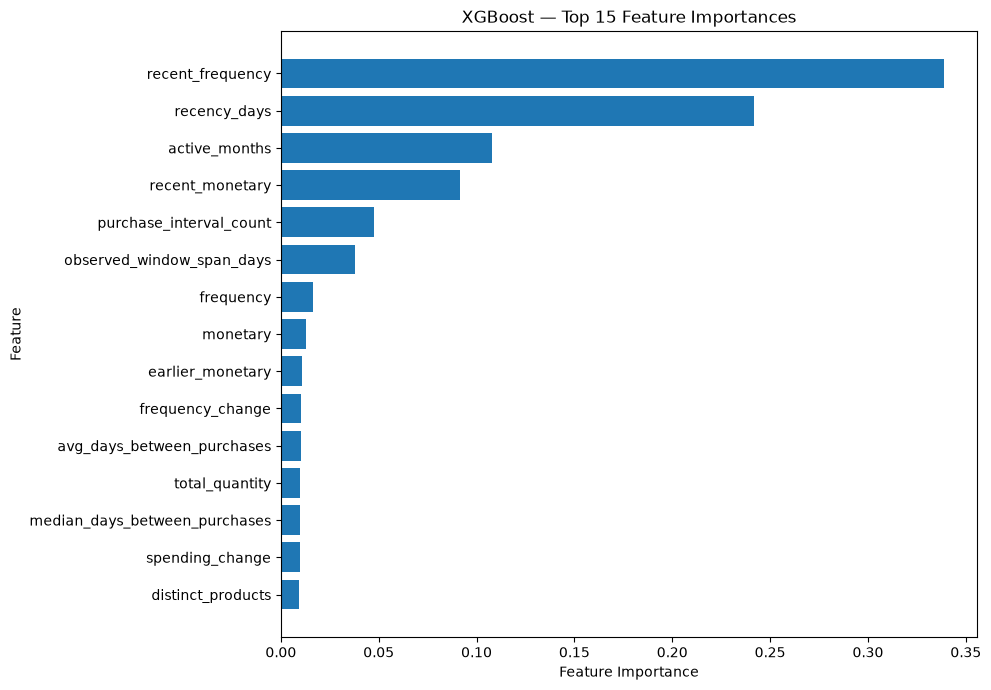

In [89]:
# RetailPulse: XGBoost feature importance
# Access the fitted imputer and classifier.
xgb_imputer = xgboost_pipeline.named_steps["imputer"]
xgb_classifier = xgboost_pipeline.named_steps["classifier"]

# Obtain names of the transformed features.
transformed_feature_names = xgb_imputer.get_feature_names_out(feature_columns)

# Extract model feature importance.
xgb_importances = xgb_classifier.feature_importances_

# Create the importance dataframe.
xgb_feature_importance = pd.DataFrame({"feature": transformed_feature_names,"importance": xgb_importances})

xgb_feature_importance = (xgb_feature_importance.sort_values("importance", ascending=False).reset_index(drop=True))

print("XGBoost feature importance — Top 15")

display(xgb_feature_importance.head(15).round(5))

# Visualize the top 15 features.
top_features = (xgb_feature_importance.head(15).sort_values("importance", ascending=True))

plt.figure(figsize=(10, 7))

plt.barh(top_features["feature"],top_features["importance"])

plt.title("XGBoost — Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Permutation importance — Top 15 features


,feature,importance_mean,importance_std
0,recency_days,0.29989,0.00161
1,recent_monetary,0.00471,0.00042
2,total_quantity,0.00380,0.00064
3,observed_window_span_days,0.00360,0.00024
4,distinct_products,0.00246,0.00036
5,active_months,0.00241,0.00051
6,recent_frequency,0.00131,0.00004
7,avg_days_between_purchases,0.00074,0.00028
8,frequency,0.00055,0.00024
9,average_order_value,0.00053,0.00022


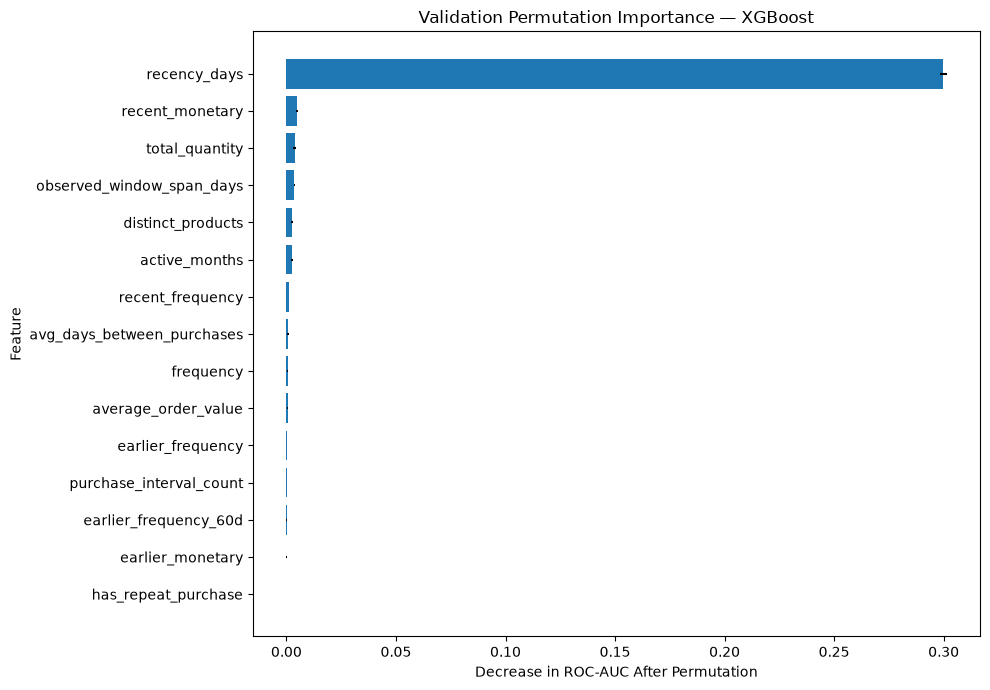

In [90]:
# RetailPulse: permutation importance on validation data

from sklearn.inspection import permutation_importance

permutation_results = permutation_importance(
    estimator=xgboost_pipeline,
    X=X_val,
    y=y_val,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "feature": X_val.columns,
    "importance_mean": permutation_results.importances_mean,
    "importance_std": permutation_results.importances_std
})

permutation_importance_df = (permutation_importance_df.sort_values("importance_mean",ascending=False).reset_index(drop=True))

print("Permutation importance — Top 15 features")

display(permutation_importance_df.head(15).round(5))

# Plot the top 15 features.
top_permutation_features = (permutation_importance_df.head(15).sort_values("importance_mean", ascending=True))

plt.figure(figsize=(10, 7))

plt.barh(
    top_permutation_features["feature"],
    top_permutation_features["importance_mean"],
    xerr=top_permutation_features["importance_std"]
)

plt.title("Validation Permutation Importance — XGBoost")
plt.xlabel("Decrease in ROC-AUC After Permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [91]:
# RetailPulse: recency-only churn baseline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Use only recency_days.
recency_features = ["recency_days"]

X_train_recency = X_train[recency_features].copy()
X_val_recency = X_val[recency_features].copy()

# Build the baseline pipeline.
recency_baseline = Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler()),
        ("classifier",LogisticRegression(class_weight="balanced",max_iter=2000,random_state=42))
    ]
)

# Fit on training data only.
recency_baseline.fit(X_train_recency,y_train)

# Generate validation probabilities.
recency_val_probabilities = (recency_baseline.predict_proba(X_val_recency)[:, 1])

# Use the same initial threshold as the other models.
recency_val_predictions = (recency_val_probabilities >= 0.50).astype(int)

# Evaluate the baseline.
recency_validation_metrics = {
    "ROC-AUC": roc_auc_score(y_val,recency_val_probabilities),
    "PR-AUC": average_precision_score(y_val,recency_val_probabilities),
    "Precision": precision_score(y_val,recency_val_predictions,zero_division=0),
    "Recall": recall_score(y_val,recency_val_predictions,zero_division=0),
    "F1-score": f1_score(y_val,recency_val_predictions,zero_division=0)
}

print("Recency-only baseline — Validation Metrics\n")

for metric, value in recency_validation_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nConfusion matrix:")

display(pd.DataFrame(
        confusion_matrix(y_val,recency_val_predictions,labels=[0, 1]),
        index=["Actual Non-Churn","Actual Churn"],
        columns=["Predicted Non-Churn","Predicted Churn"]
    )
)

print("\nClassification report:")

print(classification_report(y_val,recency_val_predictions,target_names=["Non-Churn","Churn"],zero_division=0))

Recency-only baseline — Validation Metrics

ROC-AUC: 0.9204
PR-AUC: 0.9003
Precision: 0.8086
Recall: 0.8846
F1-score: 0.8449

Confusion matrix:


,Predicted Non-Churn,Predicted Churn
Actual Non-Churn,2984,762
Actual Churn,420,3220



Classification report:
              precision    recall  f1-score   support

   Non-Churn       0.88      0.80      0.83      3746
       Churn       0.81      0.88      0.84      3640

    accuracy                           0.84      7386
   macro avg       0.84      0.84      0.84      7386
weighted avg       0.84      0.84      0.84      7386



In [92]:
# RetailPulse: compare the recency-only baseline with full models

all_model_comparison = pd.DataFrame([
    {"Model": "Recency-only Logistic Regression",**recency_validation_metrics},
    {"Model": "Logistic Regression — All Features",**validation_metrics},
    {"Model": "Random Forest",**rf_validation_metrics},
    {"Model": "XGBoost",**xgb_validation_metrics}
])

all_model_comparison = (all_model_comparison.sort_values("ROC-AUC",ascending=False).reset_index(drop=True))

display(all_model_comparison.round(4))

,Model,ROC-AUC,PR-AUC,Precision,Recall,F1-score
0,XGBoost,0.9322,0.9129,0.8242,0.9091,0.8645
1,Random Forest,0.9317,0.9082,0.8289,0.8986,0.8624
2,Logistic Regression — All Features,0.9293,0.9132,0.8347,0.8714,0.8527
3,Recency-only Logistic Regression,0.9204,0.9003,0.8086,0.8846,0.8449


In [93]:
# RetailPulse: churn target and temporal integrity audit
# Work with a copy to avoid modifying the original dataset.
audit_df = historical_churn_df.copy()

# Ensure the relevant columns are datetime values.
datetime_columns = [
    "first_purchase",
    "last_purchase",
    "snapshot_date",
    "feature_start",
    "prediction_end",
    "first_future_purchase",
    "churn_threshold_date"
]

for col in datetime_columns:
    audit_df[col] = pd.to_datetime(audit_df[col],errors="coerce")

# 1. Verify historical purchases precede the snapshot

invalid_last_purchase = (audit_df["last_purchase"]>= audit_df["snapshot_date"])

invalid_first_purchase = (audit_df["first_purchase"]< audit_df["feature_start"])

invalid_purchase_order = (audit_df["first_purchase"]> audit_df["last_purchase"])


# 2. Verify recency calculations

recalculated_recency = (audit_df["snapshot_date"]- audit_df["last_purchase"]).dt.total_seconds() / 86400

recency_difference = (recalculated_recency- audit_df["recency_days"]).abs()

invalid_recency = (recency_difference > 1e-6)

# 3. Reconstruct the churn target

CHURN_THRESHOLD_DAYS = 120

expected_threshold_date = (audit_df["last_purchase"]+ pd.Timedelta(days=CHURN_THRESHOLD_DAYS))

threshold_date_mismatch = (expected_threshold_date!= audit_df["churn_threshold_date"])

# A customer must reach the inactivity threshold
# by the end of the prediction window.
threshold_reached_in_window = (audit_df["churn_threshold_date"]<= audit_df["prediction_end"])

# A purchase on or before the threshold prevents
# the customer from crossing the threshold first.
purchase_before_or_at_threshold = (audit_df["first_future_purchase"].notna()& (
        audit_df["first_future_purchase"]<= audit_df["churn_threshold_date"]
    )
)

expected_churn = (threshold_reached_in_window& ~purchase_before_or_at_threshold).astype("int8")

target_mismatch = (expected_churn!= audit_df["churn"])

# 4. Verify future purchase dates

future_purchase_outside_window = (audit_df["first_future_purchase"].notna()& (
        (audit_df["first_future_purchase"]<= audit_df["snapshot_date"])| (audit_df["first_future_purchase"]> audit_df["prediction_end"])
    )
)


# 5. Print the audit results

audit_results = pd.DataFrame({
    "Check": [
        "Last purchase on/after snapshot",
        "First historical purchase before feature window",
        "First purchase after last purchase",
        "Recency calculation mismatch",
        "Churn threshold date mismatch",
        "Target reconstruction mismatch",
        "Future purchase outside prediction window"
    ],
    "Violations": [
        int(invalid_last_purchase.sum()),
        int(invalid_first_purchase.sum()),
        int(invalid_purchase_order.sum()),
        int(invalid_recency.sum()),
        int(threshold_date_mismatch.sum()),
        int(target_mismatch.sum()),
        int(future_purchase_outside_window.sum())
    ]
})

display(audit_results)

print("\nOriginal target distribution:")
display(
    audit_df["churn"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

print("\nReconstructed target distribution:")
display(
    expected_churn
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

print("\nOriginal churn rate:")
print(f"{audit_df['churn'].mean():.2%}")

print("\nReconstructed churn rate:")
print(f"{expected_churn.mean():.2%}")

,Check,Violations
0,Last purchase on/after snapshot,0
1,First historical purchase before feature window,0
2,First purchase after last purchase,0
3,Recency calculation mismatch,0
4,Churn threshold date mismatch,0
5,Target reconstruction mismatch,0
6,Future purchase outside prediction window,0



Original target distribution:


,customers
churn,
0,23472
1,15787



Reconstructed target distribution:


,customers
0,23472
1,15787



Original churn rate:
40.21%

Reconstructed churn rate:
40.21%


In [94]:
# RetailPulse: feature leakage audit

# These are the 20 features used in our previous models.
MODEL_FEATURES = [
    "frequency",
    "monetary",
    "total_quantity",
    "recency_days",
    "average_order_value",
    "observed_window_span_days",
    "distinct_products",
    "avg_days_between_purchases",
    "median_days_between_purchases",
    "purchase_interval_count",
    "has_repeat_purchase",
    "active_months",
    "recent_frequency",
    "recent_monetary",
    "earlier_frequency",
    "earlier_monetary",
    "earlier_frequency_60d",
    "earlier_monetary_60d",
    "spending_change",
    "frequency_change"
]

# Columns that must never be model features.
PROHIBITED_FEATURES = {
    "customer_id",
    "churn",
    "first_future_purchase",
    "future_purchase_count",
    "days_until_next_purchase",
    "churn_threshold_date",
    "threshold_in_prediction_window",
    "snapshot_date",
    "feature_start",
    "prediction_end",
    "first_purchase",
    "last_purchase"
}

# Check whether selected features exist.
missing_features = [
    col for col in MODEL_FEATURES
    if col not in historical_churn_df.columns
]

# Check for explicitly prohibited columns.
prohibited_selected = [
    col for col in MODEL_FEATURES
    if col in PROHIBITED_FEATURES
]

# Check feature data types.
non_numeric_features = [
    col for col in MODEL_FEATURES
    if col in historical_churn_df.columns
    and not pd.api.types.is_numeric_dtype(historical_churn_df[col])
]

# Check for suspicious names that may indicate
# future-derived information.
suspicious_name_patterns = [
    "future",
    "next_purchase",
    "churn_threshold",
    "prediction_end",
    "target",
    "label"
]

suspicious_features = [
    col for col in MODEL_FEATURES
    if any(
        pattern in col.lower()
        for pattern in suspicious_name_patterns
    )
]

# Display results.
print("Number of selected features:", len(MODEL_FEATURES))

print("\nMissing features:")
print(missing_features)

print("\nProhibited features selected:")
print(prohibited_selected)

print("\nNon-numeric features:")
print(non_numeric_features)

print("\nFeatures with suspicious names:")
print(suspicious_features)

# Verify feature uniqueness.
print("\nDuplicate feature names:",len(MODEL_FEATURES) - len(set(MODEL_FEATURES)))

# Automated checks.
assert len(missing_features) == 0, ("Some selected features are missing from the dataset.")

assert len(prohibited_selected) == 0, ("Prohibited columns were selected as model features.")

assert len(non_numeric_features) == 0, ("Some model features are not numeric.")

assert len(MODEL_FEATURES) == len(set(MODEL_FEATURES)), ("Duplicate model features detected.")

print("\nFeature schema checks passed.")

Number of selected features: 20

Missing features:
[]

Prohibited features selected:
[]

Non-numeric features:
[]

Features with suspicious names:
[]

Duplicate feature names: 0

Feature schema checks passed.


In [95]:
# RetailPulse: inspect return and cancellation datasets

from pathlib import Path
import pandas as pd

# Update these paths if your project structure differs.
DATA_DIR = Path("../data/processed")

returns_df = pd.read_parquet(DATA_DIR / "clean_returns.parquet")

cancelled_df = pd.read_parquet(DATA_DIR / "clean_cancelled.parquet")

datasets = {
    "Sales": sales_df,
    "Returns": returns_df,
    "Cancelled": cancelled_df
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(f"{name.upper()} DATASET")
    print("=" * 60)

    print("Shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    display(df.dtypes)

    print("\nMissing customer IDs:")
    print(df["customer_id"].isna().sum())

    print("\nUnique invoices:")
    print(df["invoice"].nunique())

    print("\nUnique identified customers:")
    print(df["customer_id"].nunique())

    print("\nDate range:")
    print("Start:", df["invoice_date"].min())
    print("End:", df["invoice_date"].max())

    print("\nCancellation flag distribution:")
    display(
        df["is_cancelled"]
        .value_counts(dropna=False)
        .rename_axis("is_cancelled")
        .to_frame("row_count")
    )

    print("\nQuantity summary:")
    display(df["quantity"].describe())

    print("\nRevenue summary:")
    display(df["revenue"].describe())

    print("\nSample records:")
    display(df.head(3))


SALES DATASET
Shape: (1007913, 11)

Columns:
['invoice', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country', 'is_cancelled', 'revenue', 'description_clean']

Data types:


invoice                      string
stock_code                   string
description                  string
quantity                      int64
invoice_date         datetime64[us]
unit_price                  float64
customer_id                   Int64
country                      string
is_cancelled                   bool
revenue                     float64
description_clean            string
dtype: object


Missing customer IDs:
228488

Unique invoices:
40077

Unique identified customers:
5878

Date range:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00

Cancellation flag distribution:


,row_count
is_cancelled,
False,1007913



Quantity summary:


...

count    19104.000000
mean       -24.959119
std        810.409329
min     -80995.000000
25%         -6.000000
50%         -2.000000
75%         -1.000000
max          1.000000
Name: quantity, dtype: float64


Revenue summary:


count     19104.000000
mean        -76.531125
std        1463.413299
min     -168469.600000
25%         -17.850000
50%          -8.950000
75%          -3.750000
max         373.570000
Name: revenue, dtype: float64


Sample records:


,invoice,stock_code,description,quantity,invoice_date,unit_price,customer_id,country,is_cancelled,revenue,description_clean
0,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia,True,-35.4,PAPER BUNTING WHITE LACE
1,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia,True,-9.9,CREAM FELT EASTER EGG BASKET
2,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia,True,-17.0,POTTING SHED SOW 'N' GROW SET


Top 10 thresholds by validation F1-score:


,threshold,precision,recall,f1_score,accuracy
0,0.36,0.7969,0.9552,0.8689,0.8580
1,0.35,0.7946,0.9574,0.8684,0.8570
2,0.37,0.7979,0.9522,0.8682,0.8576
3,0.31,0.7855,0.9701,0.8681,0.8547
4,0.38,0.7998,0.9492,0.8681,0.8578
5,0.33,0.7902,0.9624,0.8678,0.8555
6,0.41,0.8049,0.9409,0.8676,0.8585
7,0.32,0.7873,0.9659,0.8675,0.8546
8,0.40,0.8029,0.9434,0.8675,0.8580
9,0.26,0.7776,0.9808,0.8675,0.8523



Best threshold based on validation F1-score:
0.36

Metrics at the selected threshold:


,value
threshold,0.3600
precision,0.7969
recall,0.9552
f1_score,0.8689
accuracy,0.8580


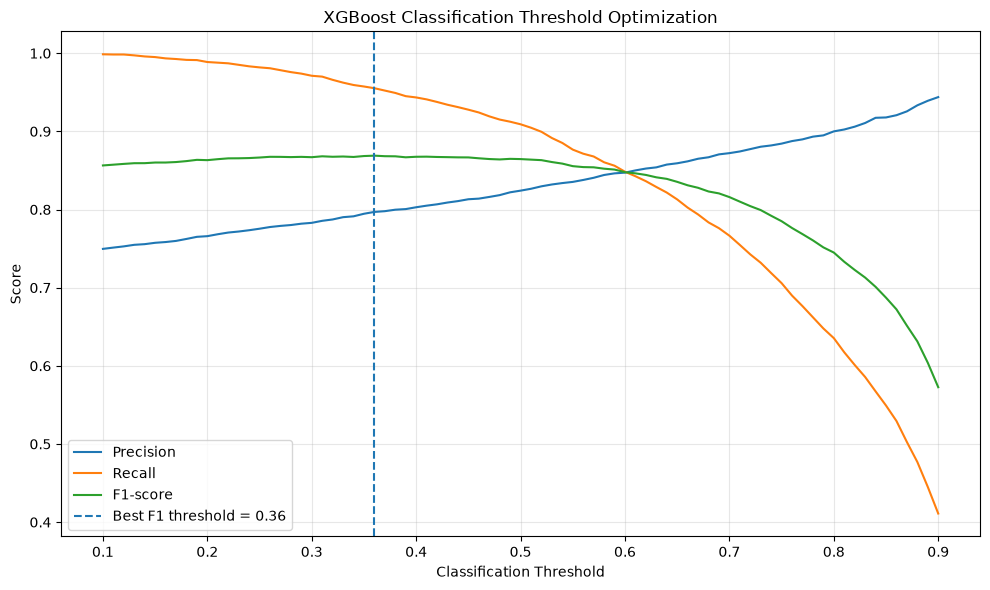

In [96]:
# RetailPulse: XGBoost Classification Threshold Optimization
from sklearn.metrics import (precision_score,recall_score,f1_score,accuracy_score)

# Use XGBoost probabilities already generated on validation data.
thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    predictions = (xgb_val_probabilities >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1_score": f1_score(y_val, predictions, zero_division=0),
        "accuracy": accuracy_score(y_val, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

# Display the thresholds with the highest F1-scores.
best_thresholds = (threshold_df.sort_values("f1_score", ascending=False).head(10).reset_index(drop=True))

print("Top 10 thresholds by validation F1-score:")

display(best_thresholds.round(4))

# Select the threshold with the highest validation F1-score.
best_threshold_row = threshold_df.loc[threshold_df["f1_score"].idxmax()]

BEST_THRESHOLD = float(best_threshold_row["threshold"])

print("\nBest threshold based on validation F1-score:")
print(round(BEST_THRESHOLD, 2))

print("\nMetrics at the selected threshold:")

display(best_threshold_row.to_frame("value").round(4))

# Visualize the precision-recall trade-off.
plt.figure(figsize=(10, 6))

plt.plot(threshold_df["threshold"],threshold_df["precision"],label="Precision")

plt.plot(threshold_df["threshold"],threshold_df["recall"],label="Recall")

plt.plot(threshold_df["threshold"],threshold_df["f1_score"],label="F1-score")

plt.axvline(BEST_THRESHOLD,linestyle="--",label=f"Best F1 threshold = {BEST_THRESHOLD:.2f}")

plt.title("XGBoost Classification Threshold Optimization")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

FINAL XGBOOST TEST RESULTS


,Model,Threshold,ROC-AUC,PR-AUC,Precision,Recall,F1-score,Accuracy
0,XGBoost,0.36,0.9277,0.8635,0.687,0.9646,0.8025,0.823



Confusion Matrix:
                  Predicted Non-Churn  Predicted Churn
Actual Non-Churn                 3199             1130
Actual Churn                       91             2480

Classification Report:
              precision    recall  f1-score   support

   Non-Churn     0.9723    0.7390    0.8397      4329
       Churn     0.6870    0.9646    0.8025      2571

    accuracy                         0.8230      6900
   macro avg     0.8297    0.8518    0.8211      6900
weighted avg     0.8660    0.8230    0.8259      6900



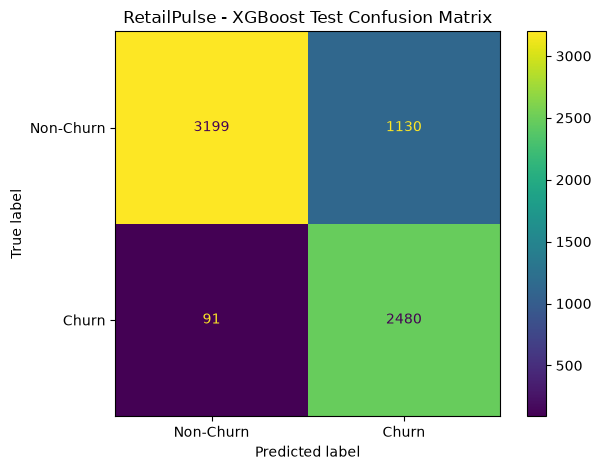


Selected threshold: 0.3599999999999999
Test observations: 6900
Test probabilities: 6900


In [97]:
# RetailPulse: Final XGBoost Evaluation on the Untouched Test Set

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Use the trained XGBoost pipeline from the previous cells.
# Do not retrain the model or modify the test data here.

FINAL_THRESHOLD = BEST_THRESHOLD

# Generate probabilities for the untouched test set.
xgb_test_probabilities = xgboost_pipeline.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data.
xgb_test_predictions = (xgb_test_probabilities >= FINAL_THRESHOLD).astype(int)

# Calculate test-set metrics.
test_metrics = {
    "Model": "XGBoost",
    "Threshold": FINAL_THRESHOLD,
    "ROC-AUC": roc_auc_score(y_test,xgb_test_probabilities),
    "PR-AUC": average_precision_score(y_test,xgb_test_probabilities),
    "Precision": precision_score(y_test,xgb_test_predictions,zero_division=0),
    "Recall": recall_score(y_test,xgb_test_predictions,zero_division=0),
    "F1-score": f1_score(y_test,xgb_test_predictions,zero_division=0),
    "Accuracy": accuracy_score(y_test,xgb_test_predictions)
}

test_metrics_df = pd.DataFrame([test_metrics])

print("FINAL XGBOOST TEST RESULTS")
display(test_metrics_df.round(4))

# Confusion matrix.
cm = confusion_matrix(y_test,xgb_test_predictions,labels=[0, 1])

print("\nConfusion Matrix:")
print(pd.DataFrame(cm,index=["Actual Non-Churn", "Actual Churn"],columns=["Predicted Non-Churn", "Predicted Churn"]))

# Detailed classification report.
print("\nClassification Report:")
print(classification_report(
        y_test,
        xgb_test_predictions,
        target_names=["Non-Churn", "Churn"],
        digits=4,
        zero_division=0
    )
)

# Visualize the confusion matrix.
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Non-Churn", "Churn"])

disp.plot(values_format="d")
plt.title("RetailPulse - XGBoost Test Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nSelected threshold:", FINAL_THRESHOLD)
print("Test observations:", len(y_test))
print("Test probabilities:", len(xgb_test_probabilities))

In [98]:
# RetailPulse: Validation vs Test Performance Comparison

import pandas as pd
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

FINAL_THRESHOLD = BEST_THRESHOLD

def calculate_metrics(y_true, probabilities, threshold):

    predictions = (np.asarray(probabilities) >= threshold).astype(int)

    return {
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities),
        "Precision": precision_score(y_true, predictions,zero_division=0),
        "Recall": recall_score(y_true, predictions,zero_division=0),
        "F1-score": f1_score(y_true, predictions,zero_division=0),
        "Accuracy": accuracy_score(y_true, predictions),
        "Churn Rate (%)": (np.mean(np.asarray(y_true)) * 100)
    }


validation_metrics = calculate_metrics(y_val, xgb_val_probabilities,FINAL_THRESHOLD)

test_metrics = calculate_metrics(y_test,xgb_test_probabilities,FINAL_THRESHOLD)

comparison_df = pd.DataFrame({"Validation": validation_metrics,"Test": test_metrics})

comparison_df["Absolute Difference"] = (comparison_df["Test"]- comparison_df["Validation"]).abs()

print("Validation vs Test Performance")
display(comparison_df.round(4))

print("\nSelected classification threshold:", FINAL_THRESHOLD)

print("\nValidation observations:",len(y_val))

print("Test observations:",len(y_test))

Validation vs Test Performance


,Validation,Test,Absolute Difference
ROC-AUC,0.9322,0.9277,0.0045
PR-AUC,0.9129,0.8635,0.0493
Precision,0.7969,0.6870,0.1099
Recall,0.9552,0.9646,0.0094
F1-score,0.8689,0.8025,0.0665
Accuracy,0.8580,0.8230,0.0349
Churn Rate (%),49.2824,37.2609,12.0216



Selected classification threshold: 0.3599999999999999

Validation observations: 7386
Test observations: 6900


In [99]:
# Use your existing customer-level feature dataset
# Replace customer_features_df with your actual variable name.

customer_scoring_df = customer_features.copy()

# The 20 features selected during model development
selected_features = [
    "frequency",
    "monetary",
    "total_quantity",
    "recency_days",
    "average_order_value",
    "observed_window_span_days",
    "distinct_products",
    "avg_days_between_purchases",
    "median_days_between_purchases",
    "purchase_interval_count",
    "has_repeat_purchase",
    "active_months",
    "recent_frequency",
    "recent_monetary",
    "earlier_frequency",
    "earlier_monetary",
    "earlier_frequency_60d",
    "earlier_monetary_60d",
    "spending_change",
    "frequency_change"
]

print("Customer scoring dataset shape:", customer_scoring_df.shape)

# Verify required features
missing_features = [
    col for col in selected_features
    if col not in customer_scoring_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing required model features: {missing_features}"
    )

print("All required model features are available.")

Customer scoring dataset shape: (3049, 21)


ValueError: Missing required model features: ['observed_window_span_days', 'has_repeat_purchase']

In [100]:
# Feature 1: Observed customer history span in days
# Uses the first and last purchase dates in the observation window.

customer_scoring_df["first_purchase"] = pd.to_datetime(
    customer_scoring_df["first_purchase"]
)

customer_scoring_df["last_purchase"] = pd.to_datetime(
    customer_scoring_df["last_purchase"]
)

customer_scoring_df["observed_window_span_days"] = (
    customer_scoring_df["last_purchase"]
    - customer_scoring_df["first_purchase"]
).dt.total_seconds() / 86400


# Feature 2: Whether the customer has made repeat purchases

customer_scoring_df["has_repeat_purchase"] = (
    customer_scoring_df["frequency"] > 1
).astype("int8")


# Inspect the new features

display(
    customer_scoring_df[
        [
            "frequency",
            "first_purchase",
            "last_purchase",
            "observed_window_span_days",
            "has_repeat_purchase"
        ]
    ].head(10)
)

print("Missing observed_window_span_days:",
      customer_scoring_df["observed_window_span_days"].isna().sum())

print("Missing has_repeat_purchase:",
      customer_scoring_df["has_repeat_purchase"].isna().sum())

,frequency,first_purchase,last_purchase,observed_window_span_days,has_repeat_purchase
customer_id,,,,,
12346,1,2011-01-18 10:01:00,2011-01-18 10:01:00,0.000000,0
12347,3,2010-12-07 14:57:00,2011-04-07 10:43:00,120.823611,1
12348,3,2010-12-16 19:09:00,2011-04-05 10:47:00,109.651389,1
12350,1,2011-02-02 16:01:00,2011-02-02 16:01:00,0.000000,0
12351,1,2010-11-29 15:23:00,2010-11-29 15:23:00,0.000000,0
12352,7,2010-11-12 10:20:00,2011-03-22 16:08:00,130.241667,1
12354,1,2011-04-21 13:11:00,2011-04-21 13:11:00,0.000000,0
12356,4,2010-11-11 14:23:00,2011-04-08 12:33:00,147.923611,1
12357,2,2010-11-16 10:05:00,2010-11-16 14:29:00,0.183333,1


Missing observed_window_span_days: 0
Missing has_repeat_purchase: 0


In [101]:
missing_features = [
    col for col in selected_features
    if col not in customer_scoring_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing required model features: {missing_features}"
    )

print("All required model features are available.")

All required model features are available.


In [102]:
# Selected threshold from validation
CHURN_THRESHOLD = 0.36

# Prepare features in the same order used during training
X_customer = customer_scoring_df[selected_features].copy()

# Generate churn probabilities
churn_probabilities = xgboost_pipeline.predict_proba(X_customer)[:, 1]

# Create prediction results
churn_predictions_df = pd.DataFrame(index=customer_scoring_df.index)

# Preserve customer IDs
if "customer_id" in customer_scoring_df.columns:
    churn_predictions_df["customer_id"] = (customer_scoring_df["customer_id"])
else:
    churn_predictions_df["customer_id"] = (customer_scoring_df.index)

churn_predictions_df["churn_probability"] = (churn_probabilities)

churn_predictions_df["churn_prediction"] = (churn_probabilities >= CHURN_THRESHOLD).astype(int)

print("Customer churn predictions generated.")

display(churn_predictions_df.head(10))

Customer churn predictions generated.


,customer_id,churn_probability,churn_prediction
customer_id,,,
12346,12346,0.978441,1
12347,12347,0.000616,0
12348,12348,0.000691,0
12350,12350,0.929673,1
12351,12351,0.994899,1
12352,12352,0.372020,1
12354,12354,0.002108,0
12356,12356,0.000842,0
12357,12357,0.995718,1


In [103]:
def assign_risk_category(probability):
    
    if probability >= 0.70:
        return "High Risk"

    elif probability >= CHURN_THRESHOLD:
        return "Medium Risk"

    else:
        return "Low Risk"


churn_predictions_df["risk_category"] = (churn_predictions_df["churn_probability"].apply(assign_risk_category))

print("Customer risk categories assigned.")

display(churn_predictions_df.sort_values("churn_probability",ascending=False).head(20))

Customer risk categories assigned.


,customer_id,churn_probability,churn_prediction,risk_category
customer_id,,,,
16445,16445,0.998423,1,High Risk
17882,17882,0.998307,1,High Risk
15001,15001,0.998266,1,High Risk
17286,17286,0.998199,1,High Risk
13646,13646,0.997948,1,High Risk
17766,17766,0.997756,1,High Risk
17360,17360,0.997636,1,High Risk
14861,14861,0.997150,1,High Risk
15224,15224,0.996863,1,High Risk


In [104]:
risk_summary = (churn_predictions_df.groupby("risk_category").agg(
        customers=("customer_id", "count"),
        average_churn_probability=("churn_probability", "mean")
    )
    .reindex(["High Risk", "Medium Risk", "Low Risk"])
)

risk_summary["customer_percentage"] = (risk_summary["customers"]/ len(churn_predictions_df)* 100)

risk_summary["average_churn_probability"] *= 100

print("Customer Churn Risk Summary:")

display(risk_summary.round(2))

print("\nTotal customers scored:",len(churn_predictions_df))

print("Customers predicted to churn:",int(churn_predictions_df["churn_prediction"].sum()))

Customer Churn Risk Summary:


,customers,average_churn_probability,customer_percentage
risk_category,,,
High Risk,1653,92.720001,54.21
Medium Risk,359,55.480000,11.77
Low Risk,1037,4.010000,34.01



Total customers scored: 3049
Customers predicted to churn: 2012


In [ ]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "customer_churn_predictions.csv"

churn_predictions_df.to_csv(output_path,index=False)

print("Predictions saved to:", output_path.resolve())

Predictions saved to: E:\RetailPulse\data\processed\customer_churn_predictions.csv


In [105]:
# RetailPulse: Prepare the eligible customer scoring population

CHURN_THRESHOLD_DAYS = 120
CHURN_PROBABILITY_THRESHOLD = 0.36

# Keep customers who have not already crossed the churn threshold.
# This assumes recency_days is calculated relative to the
# same observation cutoff used to construct the customer features.

eligible_customers_df = customer_scoring_df.loc[customer_scoring_df["recency_days"] < CHURN_THRESHOLD_DAYS].copy()

print("Original customer count:", len(customer_scoring_df))

print("Eligible active customers:", len(eligible_customers_df))

print("Excluded customers:",len(customer_scoring_df) - len(eligible_customers_df))

display(eligible_customers_df.head())

Original customer count: 3049
Eligible active customers: 2137
Excluded customers: 912


,first_purchase,last_purchase,frequency,monetary,total_quantity,recency_days,average_order_value,customer_history_days,avg_days_between_purchases,median_days_between_purchases,...,recent_monetary,earlier_frequency,earlier_monetary,earlier_frequency_60d,earlier_monetary_60d,spending_change,frequency_change,distinct_products,observed_window_span_days,has_repeat_purchase
customer_id,,,,,,,,,,,,,,,,,,,,,
12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,77183.60,74215,102.582639,77183.600000,0.000000,NaN,NaN,...,0.00,1.0,77183.60,0.5,38591.800,-38591.800,-0.5,1,0.000000,0
12347,2010-12-07 14:57:00,2011-04-07 10:43:00,3,1823.43,1117,23.553472,607.810000,120.823611,60.411806,60.411806,...,636.25,2.0,1187.18,1.0,593.590,42.660,0.0,63,120.823611,1
12348,2010-12-16 19:09:00,2011-04-05 10:47:00,3,1487.24,2124,25.550694,495.746667,109.651389,54.825694,54.825694,...,367.00,2.0,1120.24,1.0,560.120,-193.120,0.0,22,109.651389,1
12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,87.332639,334.400000,0.000000,NaN,NaN,...,0.00,1.0,334.40,0.5,167.200,-167.200,-0.5,17,0.000000,0
12352,2010-11-12 10:20:00,2011-03-22 16:08:00,7,1905.61,442,39.327778,272.230000,130.241667,21.706944,14.552778,...,280.66,5.0,1624.95,2.5,812.475,-531.815,-0.5,38,130.241667,1


In [107]:
# RetailPulse: Generate eligible customer churn predictions

# 1. Prepare features in the exact training order
X_eligible = eligible_customers_df[selected_features].copy()

# 2. Generate churn probabilities
churn_probabilities = xgboost_pipeline.predict_proba(
    X_eligible
)[:, 1]

# 3. Retrieve customer IDs from the column or index
if "customer_id" in eligible_customers_df.columns:
    customer_ids = eligible_customers_df["customer_id"].to_numpy()

elif eligible_customers_df.index.name == "customer_id":
    customer_ids = eligible_customers_df.index.to_numpy()

else:
    raise ValueError(
        "Customer IDs were not found in the DataFrame columns or index."
    )

# 4. Build the prediction DataFrame
churn_predictions_df = pd.DataFrame({
    "customer_id": customer_ids,
    "churn_probability": churn_probabilities
})

# 5. Apply the selected classification threshold
CHURN_PROBABILITY_THRESHOLD = 0.36

churn_predictions_df["churn_prediction"] = (
    churn_predictions_df["churn_probability"]
    >= CHURN_PROBABILITY_THRESHOLD
).astype(int)

# 6. Assign customer risk categories
churn_predictions_df["risk_category"] = pd.cut(
    churn_predictions_df["churn_probability"],
    bins=[-np.inf, 0.36, 0.70, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    right=False
)

# 7. Display results
print("Eligible customers scored:", len(churn_predictions_df))

print(
    "Unique customers scored:",
    churn_predictions_df["customer_id"].nunique()
)

print(
    "Predicted churn customers:",
    int(churn_predictions_df["churn_prediction"].sum())
)

print("\nCustomer risk distribution:")

display(
    churn_predictions_df["risk_category"]
    .value_counts()
    .reindex(["High Risk", "Medium Risk", "Low Risk"], fill_value=0)
    .rename("customers")
    .to_frame()
)

print("\nTop 20 customers by churn probability:")

display(
    churn_predictions_df
    .sort_values("churn_probability", ascending=False)
    .head(20)
)

Eligible customers scored: 2137
Unique customers scored: 2137
Predicted churn customers: 1100

Customer risk distribution:


,customers
risk_category,
High Risk,741
Medium Risk,359
Low Risk,1037



Top 20 customers by churn probability:


,customer_id,churn_probability,churn_prediction,risk_category
697,14221,0.995930,1,High Risk
367,13313,0.995618,1,High Risk
865,14653,0.994791,1,High Risk
833,14553,0.994169,1,High Risk
1431,16282,0.992827,1,High Risk
343,13233,0.991056,1,High Risk
59,12489,0.990734,1,High Risk
483,13656,0.990530,1,High Risk
1520,16551,0.990490,1,High Risk
327,13187,0.989847,1,High Risk


In [108]:
risk_summary = (churn_predictions_df.groupby("risk_category", observed=False).agg(
        customers=("customer_id", "count"),
        average_churn_probability=("churn_probability", "mean")
    )
)

risk_summary["customer_percentage"] = (risk_summary["customers"]/ len(churn_predictions_df)* 100)

risk_summary["average_churn_probability"] *= 100

print("RetailPulse Customer Churn Risk Summary")

display(risk_summary.round(2))

RetailPulse Customer Churn Risk Summary


,customers,average_churn_probability,customer_percentage
risk_category,,,
Low Risk,1037,4.01,48.53
Medium Risk,359,55.48,16.80
High Risk,741,85.07,34.67


In [110]:
import shap

e:\RetailPulse\.venv311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [111]:
print("SHAP version:", shap.__version__)
print("Eligible customers:", len(X_eligible))
print("Features:", len(selected_features))

SHAP version: 0.51.0
Eligible customers: 2137
Features: 20


In [112]:
# Inspect the preprocessing steps in your trained pipeline

print("Pipeline steps:")

for step_name, transformer in xgboost_pipeline.steps:
    print(f"{step_name}: {type(transformer).__name__}")

print("\nOriginal feature count:", len(selected_features))
print("Transformed feature count:", X_shap_transformed.shape[1])

Pipeline steps:
imputer: SimpleImputer
classifier: XGBClassifier

Original feature count: 20


NameError: name 'X_shap_transformed' is not defined

In [113]:
# Start with the same features used during training
X_shap = X_eligible[selected_features].copy()

# Apply preprocessing steps, excluding the final classifier
X_shap_transformed = X_shap.copy()

for step_name, transformer in xgboost_pipeline.steps[:-1]:

    X_shap_transformed = transformer.transform(X_shap_transformed)

# Retrieve the actual feature names after preprocessing
try:
    transformed_feature_names = (
        xgboost_pipeline[:-1].get_feature_names_out(selected_features)
    )

except (AttributeError, ValueError):
    transformed_feature_names = [
        f"feature_{i}"
        for i in range(X_shap_transformed.shape[1])
    ]

# Build the transformed DataFrame using the correct number of columns
X_shap_transformed = pd.DataFrame(
    X_shap_transformed,
    columns=transformed_feature_names,
    index=X_eligible.index
)

print("SHAP input shape:", X_shap_transformed.shape)
print("Number of feature names:", len(transformed_feature_names))

display(X_shap_transformed.head())

SHAP input shape: (2137, 22)
Number of feature names: 22


,frequency,monetary,total_quantity,recency_days,average_order_value,observed_window_span_days,distinct_products,avg_days_between_purchases,median_days_between_purchases,purchase_interval_count,...,recent_frequency,recent_monetary,earlier_frequency,earlier_monetary,earlier_frequency_60d,earlier_monetary_60d,spending_change,frequency_change,missingindicator_avg_days_between_purchases,missingindicator_median_days_between_purchases
customer_id,,,,,,,,,,,,,,,,,,,,,
12346,1.0,77183.60,74215.0,102.582639,77183.600000,0.000000,1.0,36.454427,36.005035,0.0,...,0.0,0.00,1.0,77183.60,0.5,38591.800,-38591.800,-0.5,1.0,1.0
12347,3.0,1823.43,1117.0,23.553472,607.810000,120.823611,63.0,60.411806,60.411806,2.0,...,1.0,636.25,2.0,1187.18,1.0,593.590,42.660,0.0,0.0,0.0
12348,3.0,1487.24,2124.0,25.550694,495.746667,109.651389,22.0,54.825694,54.825694,2.0,...,1.0,367.00,2.0,1120.24,1.0,560.120,-193.120,0.0,0.0,0.0
12350,1.0,334.40,197.0,87.332639,334.400000,0.000000,17.0,36.454427,36.005035,0.0,...,0.0,0.00,1.0,334.40,0.5,167.200,-167.200,-0.5,1.0,1.0
12352,7.0,1905.61,442.0,39.327778,272.230000,130.241667,38.0,21.706944,14.552778,6.0,...,2.0,280.66,5.0,1624.95,2.5,812.475,-531.815,-0.5,0.0,0.0


In [114]:
# Explain the trained XGBoost model

xgb_model = xgboost_pipeline.steps[-1][1]

explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer(X_shap_transformed)

print("SHAP values calculated successfully.")
print("SHAP values shape:", shap_values.values.shape)

SHAP values calculated successfully.
SHAP values shape: (2137, 22)


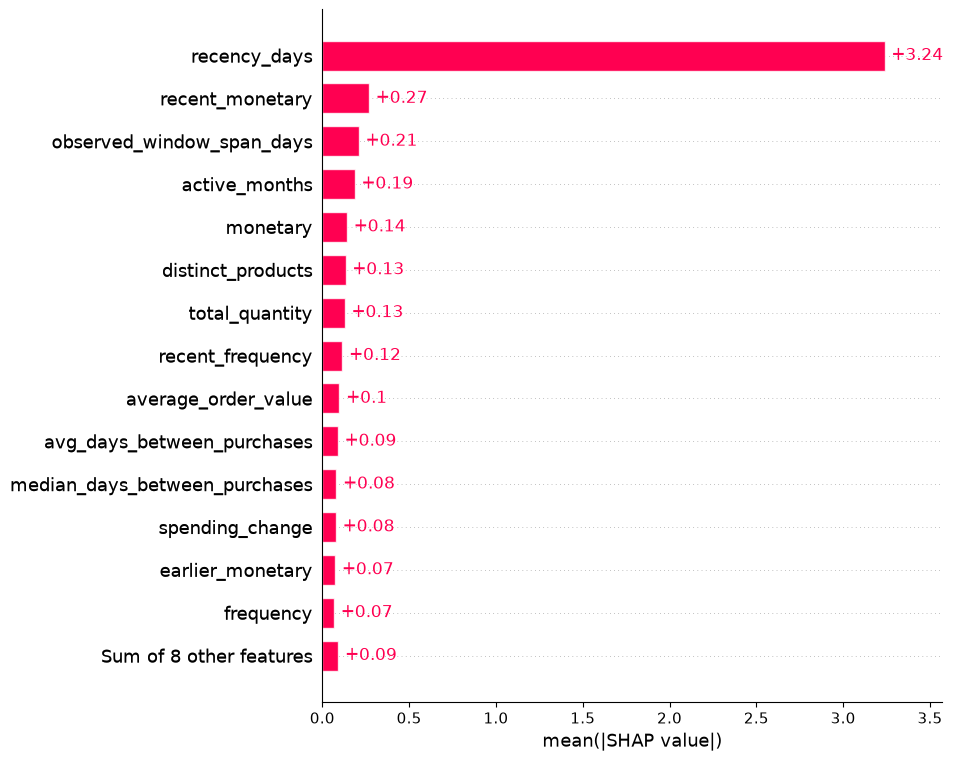

In [115]:
shap.plots.bar(shap_values,max_display=15)

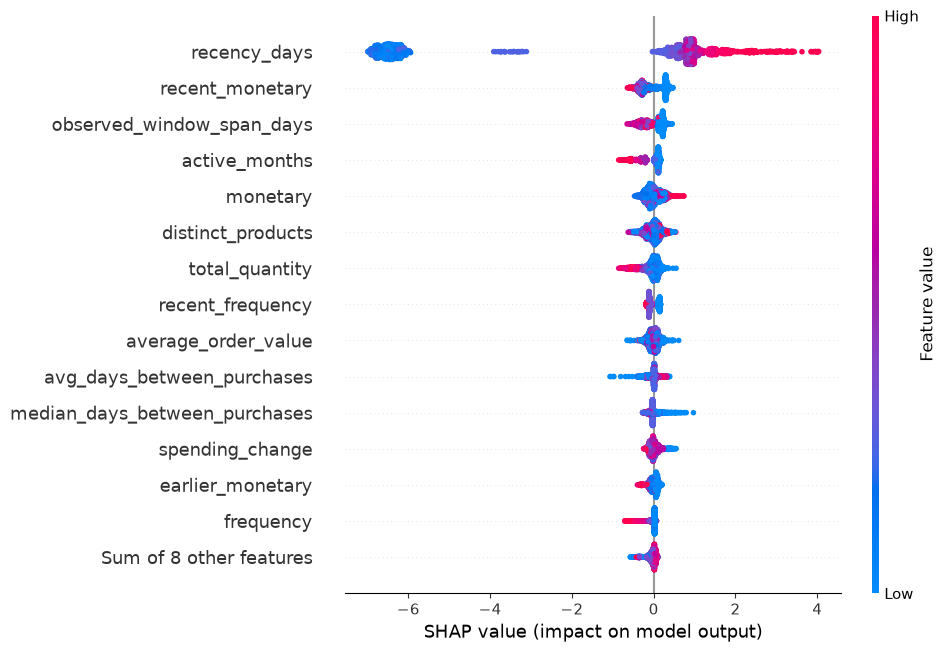

In [116]:
shap.plots.beeswarm(shap_values,max_display=15)

In [117]:
# Inspect existing SHAP output and prediction results

print("SHAP values shape:", shap_values.values.shape)

print("\nEligible customer features:")
print(X_eligible.shape)

print("\nCustomer prediction columns:")
print(churn_predictions_df.columns.tolist())

print("\nSample customer predictions:")

display(churn_predictions_df.sort_values("churn_probability", ascending=False).head(10))

SHAP values shape: (2137, 22)

Eligible customer features:
(2137, 20)

Customer prediction columns:
['customer_id', 'churn_probability', 'churn_prediction', 'risk_category']

Sample customer predictions:


,customer_id,churn_probability,churn_prediction,risk_category
697,14221,0.995930,1,High Risk
367,13313,0.995618,1,High Risk
865,14653,0.994791,1,High Risk
833,14553,0.994169,1,High Risk
1431,16282,0.992827,1,High Risk
343,13233,0.991056,1,High Risk
59,12489,0.990734,1,High Risk
483,13656,0.990530,1,High Risk
1520,16551,0.990490,1,High Risk
327,13187,0.989847,1,High Risk


In [118]:
# 1. Recover the correct transformed feature names

imputer = xgboost_pipeline.named_steps["imputer"]

shap_feature_names = imputer.get_feature_names_out(selected_features).tolist()

print("Number of SHAP features:", len(shap_feature_names))
print("Number of SHAP columns:", shap_values.values.shape[1])

assert len(shap_feature_names) == shap_values.values.shape[1], ("Feature names do not match the SHAP output.")

# 2. Create the SHAP values DataFrame


shap_df = pd.DataFrame(shap_values.values,columns=shap_feature_names,index=X_eligible.index)

print("\nSHAP DataFrame shape:", shap_df.shape)


# 3. Align customer predictions with SHAP values

customer_explanations_df = churn_predictions_df.copy()

# Ensure one row per customer
assert customer_explanations_df["customer_id"].is_unique

assert len(customer_explanations_df) == len(shap_df)

# Use positional assignment to preserve row alignment
customer_explanations_df = customer_explanations_df.reset_index(drop=True)

shap_df = shap_df.reset_index(drop=True)

customer_explanations_df = pd.concat([customer_explanations_df, shap_df],axis=1)

print("\nCustomer explanation dataset created.")
print("Dataset shape:", customer_explanations_df.shape)

display(customer_explanations_df.head())

Number of SHAP features: 22
Number of SHAP columns: 22

SHAP DataFrame shape: (2137, 22)

Customer explanation dataset created.
Dataset shape: (2137, 26)


,customer_id,churn_probability,churn_prediction,risk_category,frequency,monetary,total_quantity,recency_days,average_order_value,observed_window_span_days,...,recent_frequency,recent_monetary,earlier_frequency,earlier_monetary,earlier_frequency_60d,earlier_monetary_60d,spending_change,frequency_change,missingindicator_avg_days_between_purchases,missingindicator_median_days_between_purchases
0,12346,0.978441,1,High Risk,0.026241,0.648902,-0.420185,2.191342,0.025916,0.233818,...,0.119841,0.267663,0.010814,0.091183,-0.014710,0.019091,0.173675,-0.023475,0.0,0.0
1,12347,0.000616,0,Low Risk,-0.005657,-0.227279,-0.208374,-6.055015,0.055448,-0.229492,...,-0.090488,-0.256034,-0.001637,-0.030356,0.001375,-0.013784,-0.045372,-0.005195,0.0,0.0
2,12348,0.000691,0,Low Risk,-0.003411,-0.112679,-0.287617,-5.978639,-0.000528,-0.211817,...,-0.081816,-0.297516,-0.001844,-0.051366,0.000809,-0.022709,-0.067669,-0.002413,0.0,0.0
3,12350,0.929673,1,High Risk,0.020244,-0.057252,0.094225,1.421570,0.144443,0.224781,...,0.156041,0.301455,0.000833,0.071614,0.001787,0.011252,0.032738,-0.028692,0.0,0.0
4,12352,0.372020,1,Medium Risk,-0.125594,-0.064631,0.117934,0.443343,0.029730,-0.294766,...,-0.058096,-0.372331,-0.002394,-0.104723,-0.009318,0.011990,0.009016,-0.068260,0.0,0.0


In [119]:
# Find the top 3 positive SHAP contributors
shap_only = customer_explanations_df[shap_feature_names]

top_reasons = []

for row_idx in range(len(shap_only)):

    customer_shap = shap_only.iloc[row_idx]

    # Keep features that push the prediction toward churn
    positive_contributions = customer_shap[customer_shap > 0].sort_values(ascending=False)

    top_three = positive_contributions.head(3)

    reasons = [
        {
            "feature": feature,
            "shap_value": float(value)
        }
        for feature, value in top_three.items()
    ]

    top_reasons.append(reasons)


# Attach explanations to customers


customer_explanations_df["top_churn_reasons"] = [
    [
        item["feature"]
        for item in reasons
    ]
    for reasons in top_reasons
]

customer_explanations_df["top_churn_contributions"] = [
    [
        round(item["shap_value"], 4)
        for item in reasons
    ]
    for reasons in top_reasons
]


print("Customer-level explanations generated.")

display(
    customer_explanations_df[
        [
            "customer_id",
            "churn_probability",
            "risk_category",
            "top_churn_reasons",
            "top_churn_contributions"
        ]
    ]
    .sort_values("churn_probability",ascending=False).head(20)
)

Customer-level explanations generated.


,customer_id,churn_probability,risk_category,top_churn_reasons,top_churn_contributions
697,14221,0.995930,High Risk,"[recency_days, recent_monetary, observed_windo...","[4.0151, 0.3034, 0.1939]"
367,13313,0.995618,High Risk,"[recency_days, recent_monetary, observed_windo...","[4.0145, 0.3034, 0.1941]"
865,14653,0.994791,High Risk,"[recency_days, recent_monetary, observed_windo...","[3.9632, 0.3089, 0.201]"
833,14553,0.994169,High Risk,"[recency_days, recent_monetary, observed_windo...","[3.984, 0.31, 0.2006]"
1431,16282,0.992827,High Risk,"[recency_days, recent_monetary, observed_windo...","[3.8528, 0.2999, 0.1988]"
343,13233,0.991056,High Risk,"[recency_days, recent_monetary, observed_windo...","[3.3952, 0.3146, 0.1962]"
59,12489,0.990734,High Risk,"[recency_days, recent_monetary, average_order_...","[3.4196, 0.3011, 0.2325]"
483,13656,0.990530,High Risk,"[recency_days, recent_monetary, monetary]","[3.2463, 0.3078, 0.1977]"
1520,16551,0.990490,High Risk,"[recency_days, recent_monetary, average_order_...","[3.3658, 0.2989, 0.2176]"
327,13187,0.989847,High Risk,"[recency_days, recent_monetary, observed_windo...","[3.3782, 0.307, 0.189]"


In [120]:
# 1. Prepare customer historical value data
# Work with the existing eligible customer dataset
customer_value_df = eligible_customers_df.copy()

# customer_id may be a column or the DataFrame index
if "customer_id" not in customer_value_df.columns:

    if customer_value_df.index.name == "customer_id":
        customer_value_df = customer_value_df.reset_index()

    else:
        raise ValueError("customer_id was not found in the columns or index.")

# Keep the customer identifier and historical monetary value
if "monetary" not in customer_value_df.columns:
    raise ValueError("The monetary feature is missing from eligible_customers_df.")

customer_value_df = customer_value_df[["customer_id", "monetary"]].copy()

# Ensure one record per customer
assert customer_value_df["customer_id"].is_unique

# Historical spending should be non-negative for this calculation
customer_value_df["monetary"] = (customer_value_df["monetary"].clip(lower=0))

print("Customer value records:", len(customer_value_df))

# 2. Merge historical value with churn predictions

retention_df = customer_explanations_df.merge(
    customer_value_df,
    on="customer_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_historical")
)

if retention_df["monetary"].isna().any():
    raise ValueError("Some scored customers have no matching historical value.")

assert retention_df["customer_id"].is_unique

print("Customers in retention dataset:", len(retention_df))

display(
    retention_df[
        [
            "customer_id",
            "churn_probability",
            "risk_category",
            "monetary"
        ]
    ].head()
)

Customer value records: 2137
Customers in retention dataset: 2137


,customer_id,churn_probability,risk_category,monetary
0,12346,0.978441,High Risk,0.648902
1,12347,0.000616,Low Risk,-0.227279
2,12348,0.000691,Low Risk,-0.112679
3,12350,0.929673,High Risk,-0.057252
4,12352,0.372020,Medium Risk,-0.064631


In [121]:
# 3. Calculate normalized customer scores
# Rank churn probabilities from 0 to 1
retention_df["churn_score"] = (retention_df["churn_probability"].rank(pct=True))

# Rank historical monetary values from 0 to 1
retention_df["value_score"] = (retention_df["monetary"].rank(pct=True))

# Combined retention priority score: 0 to 100
retention_df["retention_priority_score"] = (100*(0.70 * retention_df["churn_score"]+ 0.30 * retention_df["value_score"]))

# 4. Assign retention priority categories


retention_df["retention_priority"] = pd.cut(
    retention_df["retention_priority_score"],
    bins=[-np.inf, 50, 80, np.inf],
    labels=["Low Priority","Medium Priority","High Priority"],
    right=False
)


# 5. Sort customers by retention priority

retention_df = retention_df.sort_values("retention_priority_score",ascending=False).reset_index(drop=True)

print("Retention prioritization completed.")

display(retention_df[
        [
            "customer_id",
            "churn_probability",
            "risk_category",
            "monetary",
            "retention_priority_score",
            "retention_priority",
            "top_churn_reasons"
        ]
    ].head(20)
)

Retention prioritization completed.


,customer_id,churn_probability,risk_category,monetary,retention_priority_score,retention_priority,top_churn_reasons
0,12346,0.978441,High Risk,0.648902,98.797380,High Priority,"[recency_days, monetary, distinct_products]"
1,13680,0.989088,High Risk,0.309406,98.058025,High Priority,"[recency_days, median_days_between_purchases, ..."
2,18032,0.983679,High Risk,0.305999,97.590080,High Priority,"[recency_days, monetary, recent_monetary]"
3,12665,0.971058,High Risk,0.379167,97.562003,High Priority,"[recency_days, monetary, distinct_products]"
4,14501,0.967455,High Risk,0.372482,97.304633,High Priority,"[recency_days, monetary, recent_monetary]"
5,14090,0.966706,High Risk,0.325177,96.593355,High Priority,"[recency_days, monetary, recent_monetary]"
6,17446,0.948171,High Risk,0.356554,95.797847,High Priority,"[recency_days, monetary, recent_monetary]"
7,14760,0.946330,High Risk,0.367626,95.793168,High Priority,"[recency_days, monetary, recent_monetary]"
8,13656,0.990530,High Risk,0.197712,95.418811,High Priority,"[recency_days, recent_monetary, monetary]"
9,16282,0.992827,High Risk,0.188712,95.208236,High Priority,"[recency_days, recent_monetary, observed_windo..."


In [122]:
# 6. Calculate probability-weighted historical value
retention_df["probability_weighted_historical_value"] = (retention_df["churn_probability"]* retention_df["monetary"])

# 7. Summarize customers by model risk category

risk_summary = (retention_df.groupby("risk_category", observed=True).agg(
        customers=("customer_id", "nunique"),
        average_churn_probability=("churn_probability", "mean"),
        historical_monetary_value=("monetary", "sum"),
        average_historical_value=("monetary", "mean"),
        probability_weighted_value=(
            "probability_weighted_historical_value",
            "sum"
        )
    )
    .reset_index()
)

risk_summary["average_churn_probability"] *= 100

risk_summary["historical_monetary_value"] = (risk_summary["historical_monetary_value"].round(2))

risk_summary["average_historical_value"] = (risk_summary["average_historical_value"].round(2))

risk_summary["probability_weighted_value"] = (risk_summary["probability_weighted_value"].round(2))

print("RetailPulse Customer Risk Summary")

display(risk_summary)

RetailPulse Customer Risk Summary


,risk_category,customers,average_churn_probability,historical_monetary_value,average_historical_value,probability_weighted_value
0,Low Risk,1037,4.013015,-5.620000,-0.01,-2.480000
1,Medium Risk,359,55.482147,-37.939999,-0.11,-21.030001
2,High Risk,741,85.067680,26.940001,0.04,26.940001


In [ ]:
from pathlib import Path

# Create an output directory
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save customer-level retention priorities
retention_df.to_csv(output_dir / "customer_retention_priorities.csv",index=False)

# Save the risk summary
risk_summary.to_csv(output_dir / "customer_risk_summary.csv",index=False)

print("Files saved successfully:")
print(output_dir / "customer_retention_priorities.csv")
print(output_dir / "customer_risk_summary.csv")

Files saved successfully:
..\outputs\customer_retention_priorities.csv
..\outputs\customer_risk_summary.csv


In [123]:
# Inspect monetary-related columns after the merge

print("Retention dataset monetary columns:")

print([
    col for col in retention_df.columns
    if "monetary" in col.lower()
])

print("\nSample monetary values:")

monetary_columns = [
    col for col in retention_df.columns
    if "monetary" in col.lower()
]

display(retention_df[monetary_columns].head(10))

Retention dataset monetary columns:
['monetary', 'recent_monetary', 'earlier_monetary', 'earlier_monetary_60d', 'monetary_historical']

Sample monetary values:


,monetary,recent_monetary,earlier_monetary,earlier_monetary_60d,monetary_historical
0,0.648902,0.267663,0.091183,0.019091,77183.60
1,0.309406,0.294231,-0.041952,0.031387,2391.59
2,0.305999,0.292718,0.165923,-0.006321,73.50
3,0.379167,0.288164,0.141233,-0.020987,63.00
4,0.372482,0.288593,0.142210,-0.002809,66.93
5,0.325177,0.305287,0.130633,-0.006321,76.32
6,0.356554,0.304717,0.155159,-0.002809,68.10
7,0.367626,0.290465,0.196362,-0.013851,89.20
8,0.197712,0.307843,0.065160,0.007748,162.70
9,0.188712,0.299894,0.052508,0.009839,168.30


In [124]:
# Correct historical customer monetary values


# Keep the actual historical spending column
assert "monetary_historical" in retention_df.columns

# Create a clean retention dataset
retention_df["historical_monetary"] = (pd.to_numeric(retention_df["monetary_historical"],errors="coerce"))

# Validate the monetary values
assert retention_df["historical_monetary"].notna().all()

assert retention_df["customer_id"].is_unique

print("Historical monetary values corrected.")

display(retention_df[
        [
            "customer_id",
            "churn_probability",
            "risk_category",
            "historical_monetary"
        ]
    ].head(10)
)

Historical monetary values corrected.


,customer_id,churn_probability,risk_category,historical_monetary
0,12346,0.978441,High Risk,77183.60
1,13680,0.989088,High Risk,2391.59
2,18032,0.983679,High Risk,73.50
3,12665,0.971058,High Risk,63.00
4,14501,0.967455,High Risk,66.93
5,14090,0.966706,High Risk,76.32
6,17446,0.948171,High Risk,68.10
7,14760,0.946330,High Risk,89.20
8,13656,0.990530,High Risk,162.70
9,16282,0.992827,High Risk,168.30


In [125]:
# Customer retention priority scoring


# Rank churn probability
retention_df["churn_score"] = (retention_df["churn_probability"].rank(pct=True))

# Rank historical monetary value
retention_df["value_score"] = (retention_df["historical_monetary"].rank(pct=True))

# Combined retention priority score
retention_df["retention_priority_score"] = (100 * (0.70 * retention_df["churn_score"]+ 0.30 * retention_df["value_score"]))

# Assign retention priority
retention_df["retention_priority"] = pd.cut(
    retention_df["retention_priority_score"],
    bins=[-np.inf, 50, 80, np.inf],
    labels=["Low Priority","Medium Priority","High Priority"],
    right=False
)

# Sort by priority
retention_df = retention_df.sort_values("retention_priority_score",ascending=False).reset_index(drop=True)

print("Updated customer retention priorities.")

display(retention_df[
        [
            "customer_id",
            "churn_probability",
            "risk_category",
            "historical_monetary",
            "retention_priority_score",
            "retention_priority"
        ]
    ].head(20)
)

Updated customer retention priorities.


,customer_id,churn_probability,risk_category,historical_monetary,retention_priority_score,retention_priority
0,12346,0.978441,High Risk,77183.60,98.839495,High Priority
1,13680,0.989088,High Risk,2391.59,95.994385,High Priority
2,14045,0.966455,High Risk,2638.95,94.595227,High Priority
3,17406,0.968586,High Risk,2184.42,93.851193,High Priority
4,16532,0.972916,High Risk,1910.40,93.500234,High Priority
5,14439,0.940614,High Risk,2661.24,92.929340,High Priority
6,14088,0.914230,High Risk,7544.91,92.508189,High Priority
7,15649,0.971323,High Risk,1660.35,92.283575,High Priority
8,15100,0.952407,High Risk,1976.70,92.058961,High Priority
9,16350,0.970636,High Risk,1202.12,89.583528,High Priority


In [126]:
# Customer risk and historical spending summary

retention_df["probability_weighted_historical_value"] = (retention_df["churn_probability"]* retention_df["historical_monetary"])

risk_summary = (retention_df.groupby("risk_category", observed=True).agg(
        customers=("customer_id", "nunique"),
        average_churn_probability=("churn_probability", "mean"),
        historical_monetary_value=("historical_monetary", "sum"),
        average_historical_value=("historical_monetary", "mean"),
        probability_weighted_value=("probability_weighted_historical_value","sum")
    )
    .reset_index()
)

risk_summary["average_churn_probability"] *= 100

print("RetailPulse Customer Risk Summary")

display(risk_summary.round(2))

RetailPulse Customer Risk Summary


,risk_category,customers,average_churn_probability,historical_monetary_value,average_historical_value,probability_weighted_value
0,Low Risk,1037,4.01,2561261.81,2469.88,78942.19
1,Medium Risk,359,55.48,373984.35,1041.74,202528.93
2,High Risk,741,85.07,436799.72,589.47,375780.44


In [ ]:
from pathlib import Path

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

retention_df.to_csv(output_dir / "customer_retention_priorities.csv",index=False)

risk_summary.to_csv(output_dir / "customer_risk_summary.csv",index=False)

print("Corrected outputs saved successfully.")

Corrected outputs saved successfully.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

# Convert labels and probabilities into NumPy arrays
y_test_array = np.asarray(y_test).ravel()
y_test_proba = np.asarray(xgb_test_probabilities).ravel()

# Check that labels and probabilities match
assert len(y_test_array) == len(y_test_proba), ("Test labels and probabilities have different lengths.")

# Check for invalid probability values
assert np.isfinite(y_test_proba).all(), ("Predicted probabilities contain NaN or infinite values.")

assert ((y_test_proba >= 0) & (y_test_proba <= 1)).all(), ("Predicted probabilities must be between 0 and 1.")

# Calculate metrics
brier = brier_score_loss(y_test_array, y_test_proba)
logloss = log_loss(y_test_array, y_test_proba)
roc_auc = roc_auc_score(y_test_array, y_test_proba)

calibration_metrics = pd.DataFrame({
    "Metric": ["Brier Score","Log Loss","ROC-AUC",],
    "Value": [brier,logloss,roc_auc,],
})

display(calibration_metrics.round(4))

,Metric,Value
0,Brier Score,0.1091
1,Log Loss,0.3254
2,ROC-AUC,0.9277


In [128]:
# Create probability bands
calibration_df = pd.DataFrame({"actual_churn": y_test_array,"predicted_probability": y_test_proba,})

calibration_df["probability_band"] = pd.cut(
    calibration_df["predicted_probability"],
    bins=[0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    include_lowest=True,
)

calibration_table = (
    calibration_df
    .groupby("probability_band", observed=True)
    .agg(
        customers=("actual_churn", "size"),
        average_predicted_probability=("predicted_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean"),
    )
    .reset_index()
)

calibration_table["average_predicted_probability"] *= 100
calibration_table["actual_churn_rate"] *= 100

display(calibration_table.round(2))

,probability_band,customers,average_predicted_probability,actual_churn_rate
0,"(-0.001, 0.1]",2875,0.180000,0.21
1,"(0.1, 0.2]",110,15.440000,12.73
2,"(0.2, 0.3]",185,25.180000,22.16
3,"(0.3, 0.4]",215,35.279999,27.44
4,"(0.4, 0.5]",238,45.299999,39.92
5,"(0.5, 0.6]",330,55.240002,45.76
6,"(0.6, 0.7]",432,65.110001,51.16
7,"(0.7, 0.8]",631,75.419998,61.97
8,"(0.8, 0.9]",839,85.889999,76.88
9,"(0.9, 1.0]",1045,95.269997,90.72


In [129]:
from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

# Use the existing test labels and probabilities
y_test_array = np.asarray(y_test).ravel()
y_test_proba = np.asarray(y_test_proba).ravel()

# Basic validation
assert len(y_test_array) == len(y_test_proba)

assert np.isfinite(y_test_proba).all()

assert np.all((y_test_proba >= 0) & (y_test_proba <= 1)), "Probabilities must be between 0 and 1."

# Check the data
print("Number of test rows:", len(y_test_array))
print("Actual churn rate:", round(y_test_array.mean(), 4))
print("Mean predicted probability:", round(y_test_proba.mean(), 4))
print("Minimum probability:", round(y_test_proba.min(), 4))
print("Maximum probability:", round(y_test_proba.max(), 4))

# Build calibration dataset
calibration_df = pd.DataFrame({
    "actual_churn": y_test_array,
    "predicted_probability": y_test_proba,
})

# Explicit probability intervals
bins = np.linspace(0, 1, 11)

calibration_df["probability_band"] = pd.cut(
    calibration_df["predicted_probability"],
    bins=bins,
    include_lowest=True,
)

# Calculate observed and predicted rates
calibration_table = (
    calibration_df
    .groupby("probability_band", observed=True)
    .agg(
        customers=("actual_churn", "size"),
        average_predicted_probability=("predicted_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean"),
    )
    .reset_index()
)

# Convert probabilities to percentages exactly once
calibration_table["average_predicted_probability"] *= 100
calibration_table["actual_churn_rate"] *= 100

display(calibration_table.round(2))

# Recalculate evaluation metrics
print("\nBrier Score:", round(brier_score_loss(y_test_array, y_test_proba), 4))

print("Log Loss:", round(log_loss(y_test_array, y_test_proba), 4))

print("ROC-AUC:", round(roc_auc_score(y_test_array, y_test_proba), 4))

Number of test rows: 6900
Actual churn rate: 0.3726
Mean predicted probability: 0.4215
Minimum probability: 0.0
Maximum probability: 0.9984


,probability_band,customers,average_predicted_probability,actual_churn_rate
0,"(-0.001, 0.1]",2875,0.180000,0.21
1,"(0.1, 0.2]",110,15.440000,12.73
2,"(0.2, 0.3]",185,25.180000,22.16
3,"(0.3, 0.4]",215,35.279999,27.44
4,"(0.4, 0.5]",238,45.299999,39.92
5,"(0.5, 0.6]",330,55.240002,45.76
6,"(0.6, 0.7]",432,65.110001,51.16
7,"(0.7, 0.8]",631,75.419998,61.97
8,"(0.8, 0.9]",839,85.889999,76.88
9,"(0.9, 1.0]",1045,95.269997,90.72



Brier Score: 0.1091
Log Loss: 0.3254
ROC-AUC: 0.9277


In [130]:
import numpy as np
import pandas as pd

y = np.asarray(y_test).ravel()
p = np.asarray(y_test_proba).ravel()

# Inspect actual values and alignment
print("Test rows:", len(y))
print("Probability rows:", len(p))
print("Actual churn rate:", y.mean())
print("Mean predicted probability:", p.mean())

print("\nFirst 10 probabilities:")
print(p[:10])

# Verify probability-band assignment
diagnostic_df = pd.DataFrame({"actual_churn": y,"predicted_probability": p,})

diagnostic_df["probability_band"] = pd.cut(
    diagnostic_df["predicted_probability"],
    bins=np.linspace(0, 1, 11),
    include_lowest=True,
)

check = (
    diagnostic_df.groupby("probability_band", observed=True)
    .agg(
        customers=("actual_churn", "size"),
        minimum_probability=("predicted_probability", "min"),
        maximum_probability=("predicted_probability", "max"),
        average_probability=("predicted_probability", "mean"),
        actual_churn_rate=("actual_churn", "mean"),
    )
)

display(check.round(4))

Test rows: 6900
Probability rows: 6900
Actual churn rate: 0.3726086956521739
Mean predicted probability: 0.42145747

First 10 probabilities:
[0.00128497 0.6833715  0.8822795  0.9193415  0.8344171  0.76474285
 0.6890868  0.00231499 0.8080994  0.52709275]


,customers,minimum_probability,maximum_probability,average_probability,actual_churn_rate
probability_band,,,,,
"(-0.001, 0.1]",2875,0.0000,0.0993,0.0018,0.0021
"(0.1, 0.2]",110,0.1026,0.1997,0.1544,0.1273
"(0.2, 0.3]",185,0.2008,0.2987,0.2518,0.2216
"(0.3, 0.4]",215,0.3005,0.3975,0.3528,0.2744
"(0.4, 0.5]",238,0.4008,0.4992,0.4530,0.3992
"(0.5, 0.6]",330,0.5000,0.5986,0.5524,0.4576
"(0.6, 0.7]",432,0.6008,0.6999,0.6511,0.5116
"(0.7, 0.8]",631,0.7000,0.8000,0.7542,0.6197
"(0.8, 0.9]",839,0.8003,0.9000,0.8589,0.7688


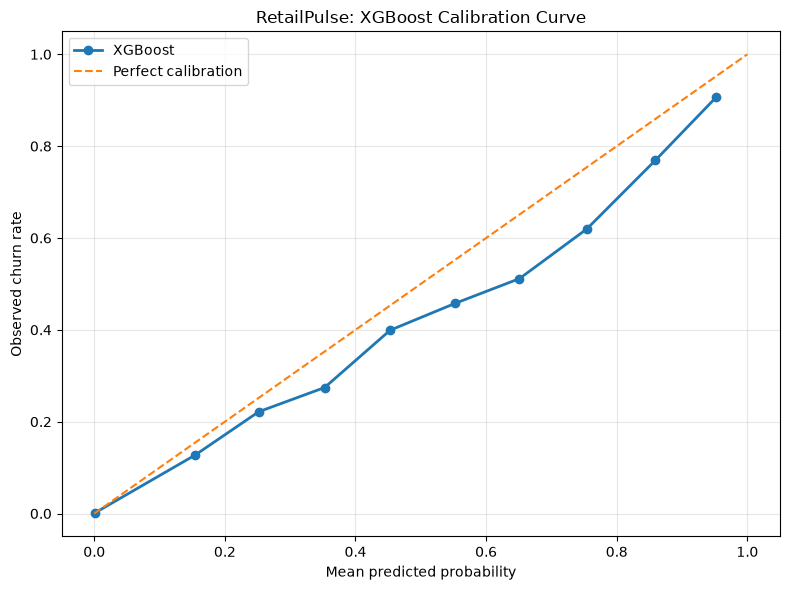

In [131]:
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve

# Calculate calibration curve using the existing test predictions
observed_rate, mean_predicted = calibration_curve(
    y_test_array,
    y_test_proba,
    n_bins=10,
    strategy="uniform",
)

plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted,
    observed_rate,
    marker="o",
    linewidth=2,
    label="XGBoost",
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed churn rate")
plt.title("RetailPulse: XGBoost Calibration Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [132]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

print("Model:", type(xgboost_pipeline).__name__)

X_train: (11706, 20)
X_val: (7386, 20)
X_test: (6900, 20)
y_train: (11706,)
y_val: (7386,)
y_test: (6900,)
Model: Pipeline
